In [2]:
from cytetype import CyteType
import scanpy as sc

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [3]:
adata = sc.read_h5ad('/Users/christoffer/work/karolinska/development/oligo-mtDSB/data/mtDNA_DSB_5k_clustered_annotation_with_rbd_2.h5ad')

In [4]:
adata.obs.genotype

aaaaakjg-1    PlptTA
aaaaikjn-1    PlptTA
aaaapoln-1    PlptTA
aaacmkgf-1    PlptTA
aaaefdnf-1    PlptTA
               ...  
oifndkbo-1    PlptTA
oifolalk-1    PlptTA
oifphdni-1    PlptTA
oigabhlk-1    PlptTA
oigafpoe-1    PlptTA
Name: genotype, Length: 980474, dtype: category
Categories (3, object): ['PlptTA', 'PlptTA:mtPst1', 'mtPst1']

In [4]:
sc.tl.rank_genes_groups(adata, groupby = 'leiden_3')

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:456: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indic

In [5]:
adata.var = adata.var.reset_index()

/Users/christoffer/miniconda3/envs/sc_py312/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [6]:
adata.var['gene_symbols'] = adata.var['index']

In [7]:
adata.var['gene_symbols']

0       2610035D17Rik
1       9630013A20Rik
2                A1cf
3                 A2m
4                Aatf
            ...      
5096           Zswim9
5097             Zup1
5098              Zyx
5099            Zzef1
5100                a
Name: gene_symbols, Length: 5101, dtype: object

In [8]:
adata.var = adata.var.set_index('index')

In [11]:
study_context = (
    "Mouse brain tissue from an experimental model of mitochondrial DNA double-strand break (mtDSB)–induced neuroinflammation. these double stranded breaks are induces specifically in the oligodendrocytes either at p21 or p60 (different stages of oligo maturity)"
    "This model induces an 'inside-out' demyelination process driven by oligodendrocyte mitochondrial stress, "
    "leading to secondary activation of glial and immune populations and progressive neuroinflammatory lesion formation. "
    "The dataset includes multiple CNS cell types (oligodendrocytes, astrocytes, microglia, neurons) "
    "captured across different  stages to map the cellular and metabolic responses to mitochondrial dysfunction. though there are no lesions present"
)

In [12]:
# ------ CyteType ------
annotator = CyteType(ad, group_key="leiden_3")
adata = annotator.run(
    study_context=study_context,
)



Using coordinates from 'X_umap' for visualization.
Calculating expression percentages.
Extracting marker genes.
Preparing visualization data with sampling.
Sampled 1000 cells from group '29' (originally 15554 cells)
Sampled 1000 cells from group '30' (originally 15172 cells)
Sampled 1000 cells from group '10' (originally 25206 cells)
Sampled 1000 cells from group '17' (originally 19830 cells)
Sampled 1000 cells from group '23' (originally 17295 cells)
Sampled 1000 cells from group '6' (originally 28504 cells)
Sampled 1000 cells from group '5' (originally 28916 cells)
Sampled 1000 cells from group '22' (originally 17516 cells)
Sampled 1000 cells from group '25' (originally 17197 cells)
Sampled 1000 cells from group '4' (originally 30745 cells)
Sampled 1000 cells from group '47' (originally 8825 cells)
Sampled 1000 cells from group '49' (originally 8114 cells)
Sampled 1000 cells from group '50' (originally 8093 cells)
Sampled 1000 cells from group '1' (originally 31640 cells)
Sampled 100

In [13]:
adata.obs['cytetype_annotation_leiden_3']

aaaaakjg-1    Mature Myelinating Oligodendrocyte (progenitor...
aaaaikjn-1                   Layer 5 Cortical Excitatory Neuron
aaaapoln-1                    Cortical Excitatory Neuron (L5/6)
aaacmkgf-1                   Layer 5 Cortical Excitatory Neuron
aaaefdnf-1    Mature Myelinating Oligodendrocyte (myelin pro...
                                    ...                        
oifndkbo-1                                   Thalamic Astrocyte
oifolalk-1                        Hypothalamic GABAergic Neuron
oifphdni-1                        Astrocyte (GABA-transporting)
oigabhlk-1                        Hypothalamic GABAergic Neuron
oigafpoe-1    Mature Myelinating Oligodendrocyte (myelin pro...
Name: cytetype_annotation_leiden_3, Length: 980474, dtype: category
Categories (61, object): ['Astrocyte (GABA-transporting)', 'Astrocyte (demyelination-responsive)', 'Astrocyte (heterogeneous)', 'Astrocyte (mature contaminated)', ..., 'Striatal Medium Spiny Neuron (ventral Penk-)', 'Thalamic As

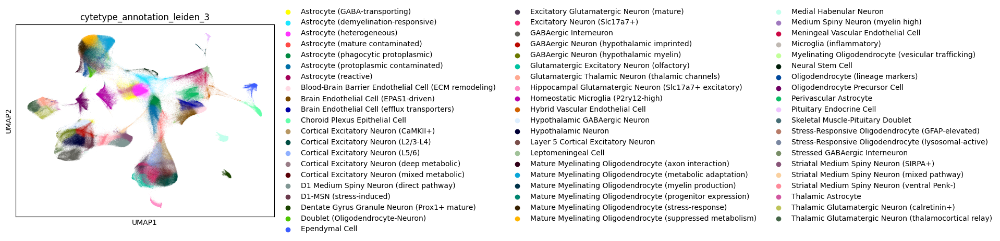

In [14]:
sc.pl.umap(adata, color = 'cytetype_annotation_leiden_3')

In [15]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors
import warnings
warnings.filterwarnings("ignore")


def plot_spatial_compact_fast(
    ad,
    color="leiden_2",
    groupby="sample_id",
    spot_size=8,
    cols=3,
    height=8,
    legend_col_width=1.2,
    palette=None,            # dict {cat:"#hex"} or list
    rasterized=True,         # big speedup for vectors/PDFs
    invert_y=True,           # match Scanpy orientation
    dpi=120,                 # lower dpi → faster
):
    # ----- 0) Preconditions -----
    if "spatial" not in ad.obsm:
        raise ValueError("ad.obsm['spatial'] is required.")

    coords = np.asarray(ad.obsm["spatial"])[:, :2]
    cats = ad.obs[color].astype("category")
    cat_names = cats.cat.categories
    cat_codes = cats.cat.codes.to_numpy()  # -1 for NaN

    # ----- 1) Build shared palette (RGBA array) -----
    if isinstance(palette, dict):
        col_list = [palette[c] for c in cat_names]
    elif isinstance(palette, (list, tuple)):
        if len(palette) < len(cat_names):
            raise ValueError("Palette shorter than number of categories.")
        col_list = list(palette)[:len(cat_names)]
    elif f"{color}_colors" in ad.uns:
        col_list = list(ad.uns[f"{color}_colors"])
        if len(col_list) != len(cat_names):
            raise ValueError(f"{color}_colors length != categories.")
    else:
        base = getattr(getattr(__import__("scanpy").pl.palettes, "default_64", []), "__iter__", None)
        base = list(__import__("scanpy").pl.palettes.default_64
                    if hasattr(__import__("scanpy").pl.palettes, "default_64")
                    else __import__("scanpy").pl.palettes.default_102)
        reps = int(np.ceil(len(cat_names) / len(base)))
        col_list = (base * reps)[:len(cat_names)]

    # store for consistency elsewhere
    ad.uns[f"{color}_colors"] = col_list

    # convert to RGBA float array for fast indexing
    rgba = np.array([mcolors.to_rgba(c) for c in col_list], dtype=float)
    # map codes -> rgba; handle -1 (NaN) as transparent
    colors_arr = np.empty((cat_codes.size, 4), dtype=float)
    colors_arr[cat_codes >= 0] = rgba[cat_codes[cat_codes >= 0]]
    colors_arr[cat_codes < 0] = (0, 0, 0, 0)

    # ----- 2) Precompute group indices (no per-iteration masks) -----
    gvals = ad.obs[groupby].astype(str).to_numpy()
    uniq_groups, gcodes = np.unique(gvals, return_inverse=True)
    # list of index arrays per group
    group_indices = [np.flatnonzero(gcodes == gi) for gi in range(len(uniq_groups))]

    # ----- 3) Figure layout -----
    n = len(uniq_groups)
    rows = int(np.ceil(n / cols))
    panel_w = height * cols * 0.6 / rows
    fig_w = panel_w + legend_col_width

    plt.ioff()  # speed: disable interactive redraws
    fig = plt.figure(figsize=(fig_w, height), dpi=dpi, constrained_layout=False)
    gs = GridSpec(
        rows, cols + 1, figure=fig,
        width_ratios=[1]*cols + [legend_col_width / (fig_w - legend_col_width)],
        wspace=0.02, hspace=0.02
    )

    # ----- 4) Panels (fast scatter) -----
    for i, sid in enumerate(uniq_groups):
        r, c = divmod(i, cols)
        ax = fig.add_subplot(gs[r, c])

        idx = group_indices[i]
        if idx.size:
            xy = coords[idx]
            # note: turn off edgecolor & use rasterized for speed
            sca = ax.scatter(
                xy[:, 0], xy[:, 1],
                c=colors_arr[idx],
                s=spot_size,
                marker='o',
                linewidths=0,
                rasterized=rasterized
            )
        ax.set_title(str(sid), fontsize=9, pad=2)
        ax.set_aspect("equal")
        if invert_y:
            ax.invert_yaxis()
        ax.set_axis_off()

    # blank unused
    for j in range(n, rows * cols):
        r, c = divmod(j, cols)
        fig.add_subplot(gs[r, c]).axis("off")

    # ----- 5) Legend (single, shared) -----
    ax_leg = fig.add_subplot(gs[:, -1])
    ax_leg.axis("off")
    handles = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=col_list[k], markersize=7, label=str(cat))
        for k, cat in enumerate(cat_names)
    ]
    ax_leg.legend(handles=handles, title=color, frameon=False, loc="center left")

    fig.subplots_adjust(left=0.01, right=0.98, top=0.98, bottom=0.02, wspace=0.02, hspace=0.02)
    plt.ion()  # ✅ correct
    plt.show()

Plotting cytetype_annotation_leiden_3 …


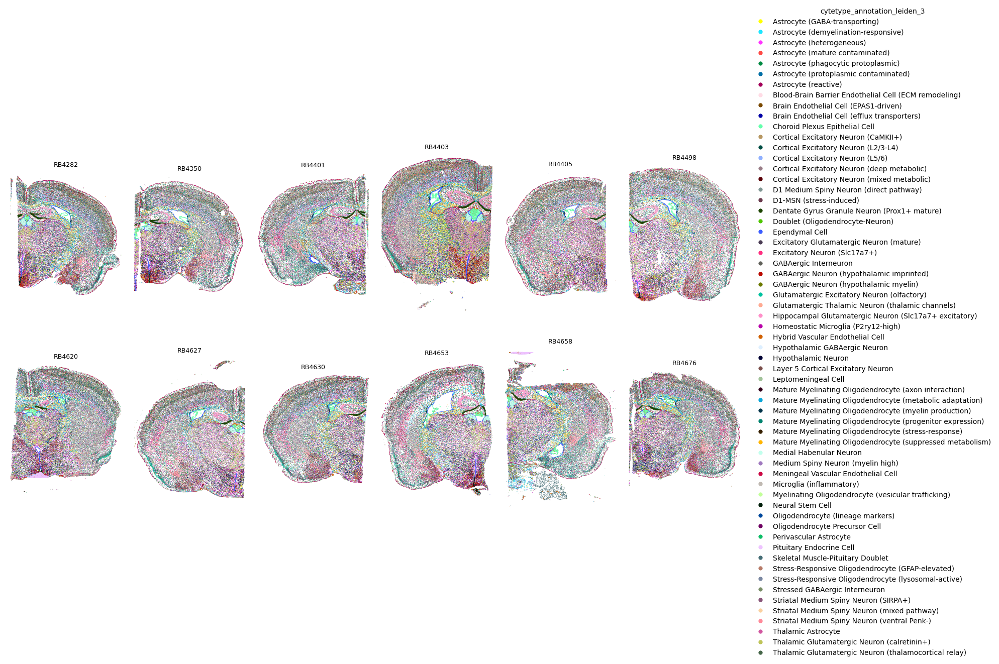

In [16]:
for domain in ['cytetype_annotation_leiden_3']:
    if domain in adata.obs.columns:
        print(f"Plotting {domain} …")
        plot_spatial_compact_fast(
            adata,
            color=domain,
            groupby="sample_id",
            spot_size=0.3,
            cols=6,
            height=8,
            legend_col_width=1.0,
            rasterized=True,   # big speedup for large data
            dpi=100             # lower = faster preview
        )
    else:
        print(f"Skipping {domain} — not in adata.obs")

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors

def plot_spatial_highlight(
    ad,
    color,                      # obs column with categories
    highlight,                  # one category to highlight
    groupby="sample_id",
    spot_size=12,
    cols=3,
    height=7,
    flip_y=True,
    fix_limits=True,            # same axes for all panels
    base_color="#B0B0B0",       # de-emphasized others
    base_alpha=0.15,
    palette=None,               # dict {cat:"#hex"} or list; if None try ad.uns[f"{color}_colors"]
    rasterized=True,
    dpi=120,
):
    if "spatial" not in ad.obsm:
        raise ValueError("ad.obsm['spatial'] is required.")
    coords = np.asarray(ad.obsm["spatial"])[:, :2]

    # categories & palette
    cats = ad.obs[color].astype("category")
    cat_names = list(cats.cat.categories)
    if isinstance(palette, dict):
        col_list = [palette.get(c, "#377eb8") for c in cat_names]
    elif isinstance(palette, (list, tuple)) and len(palette) >= len(cat_names):
        col_list = list(palette)[:len(cat_names)]
    elif f"{color}_colors" in ad.uns and len(ad.uns[f"{color}_colors"]) == len(cat_names):
        col_list = list(ad.uns[f"{color}_colors"])
    else:
        # fallback: simple cycle
        from scanpy.pl import palettes
        base = palettes.default_64 if hasattr(palettes, "default_64") else palettes.default_102
        reps = int(np.ceil(len(cat_names) / len(base)))
        col_list = (base * reps)[:len(cat_names)]

    # pick highlight color
    if highlight not in cat_names:
        raise ValueError(f"'{highlight}' not found in ad.obs['{color}'] categories.")
    h_idx = cat_names.index(highlight)
    hl_hex = col_list[h_idx]
    hl_rgba = np.array(mcolors.to_rgba(hl_hex), float)

    # precompute color array: highlight vs base
    base_rgba = np.array(mcolors.to_rgba(base_color), float)
    base_rgba[3] = base_alpha

    cat_codes = cats.cat.codes.to_numpy()  # -1 for NaN
    is_highlight = (cat_codes == h_idx)
    # initialize all as base, then overwrite highlights
    colors_arr = np.empty((cat_codes.size, 4), dtype=float)
    colors_arr[:] = base_rgba
    colors_arr[is_highlight] = hl_rgba
    # transparent for NaN
    colors_arr[cat_codes < 0] = (0, 0, 0, 0)

    # group indices (preserve observed order if possible)
    gseries = ad.obs[groupby]
    if pd.api.types.is_categorical_dtype(gseries):
        uniq_groups = list(gseries.cat.categories)
        # keep only those present
        uniq_groups = [g for g in uniq_groups if (gseries == g).any()]
        gcodes = pd.Categorical(gseries, categories=uniq_groups, ordered=True).codes
    else:
        uniq_groups = list(pd.unique(gseries))  # preserves first-appearance order
        mapping = {g:i for i,g in enumerate(uniq_groups)}
        gcodes = gseries.map(mapping).to_numpy()
    group_indices = [np.flatnonzero(gcodes == i) for i in range(len(uniq_groups))]

    # common limits (global) if requested
    if fix_limits:
        x_min, y_min = coords.min(axis=0)
        x_max, y_max = coords.max(axis=0)

    # layout
    n = len(uniq_groups)
    rows = int(np.ceil(n / cols))
    panel_w = height * cols * 0.6 / rows
    fig_w = panel_w  # legend-free; keep compact
    plt.ioff()
    fig = plt.figure(figsize=(fig_w, height), dpi=dpi, constrained_layout=False)
    gs = GridSpec(rows, cols, figure=fig, wspace=0.02, hspace=0.02)

    # panels
    axes = []
    for i, sid in enumerate(uniq_groups):
        r, c = divmod(i, cols)
        ax = fig.add_subplot(gs[r, c])
        idx = group_indices[i]
        if idx.size:
            xy = coords[idx]
            ax.scatter(
                xy[:, 0], xy[:, 1],
                c=colors_arr[idx],
                s=spot_size,
                marker='o',
                linewidths=0,
                rasterized=rasterized
            )
        ax.set_title(f"{sid} \n {highlight}", fontsize=6, pad=2)
        ax.set_aspect("equal")
        if flip_y:
            ax.invert_yaxis()
        if fix_limits:
            ax.set_xlim(x_min, x_max)
            ax.set_ylim(y_max, y_min) if flip_y else ax.set_ylim(y_min, y_max)
        ax.set_axis_off()
        axes.append(ax)

    # blank unused
    for j in range(n, rows * cols):
        r, c = divmod(j, cols)
        fig.add_subplot(gs[r, c]).axis("off")

    plt.ion()
    return fig, axes

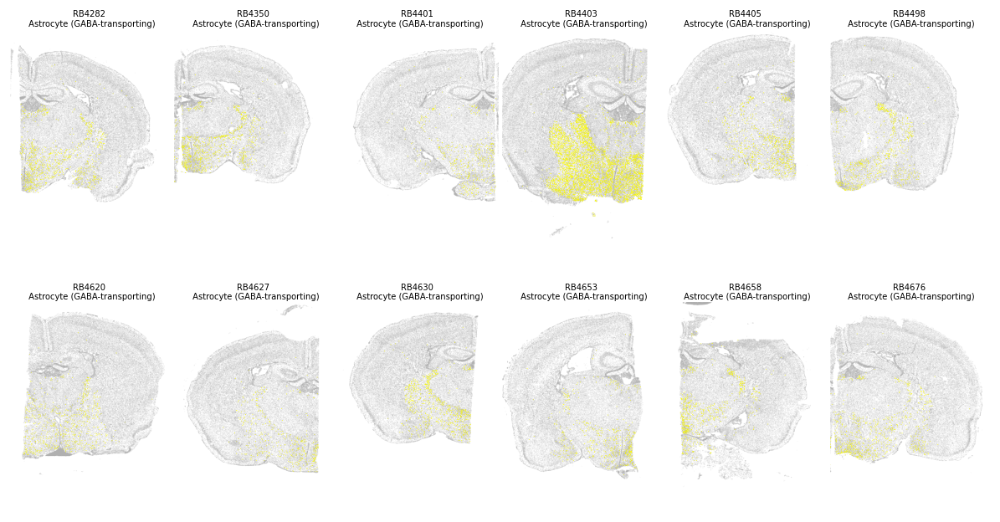

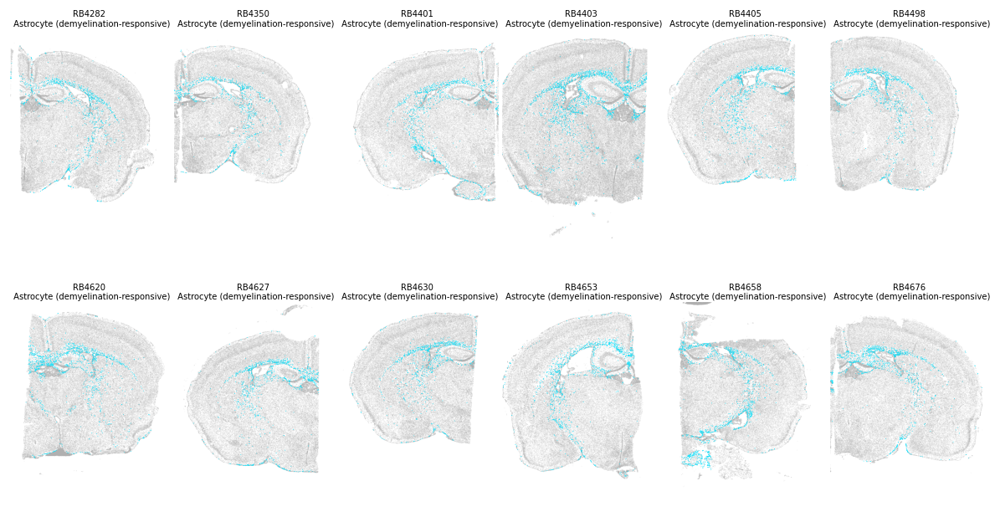

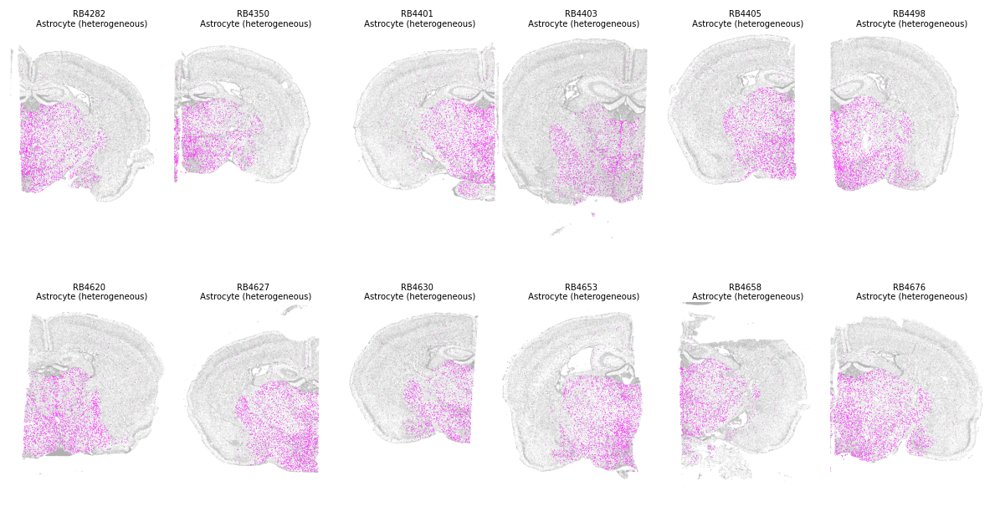

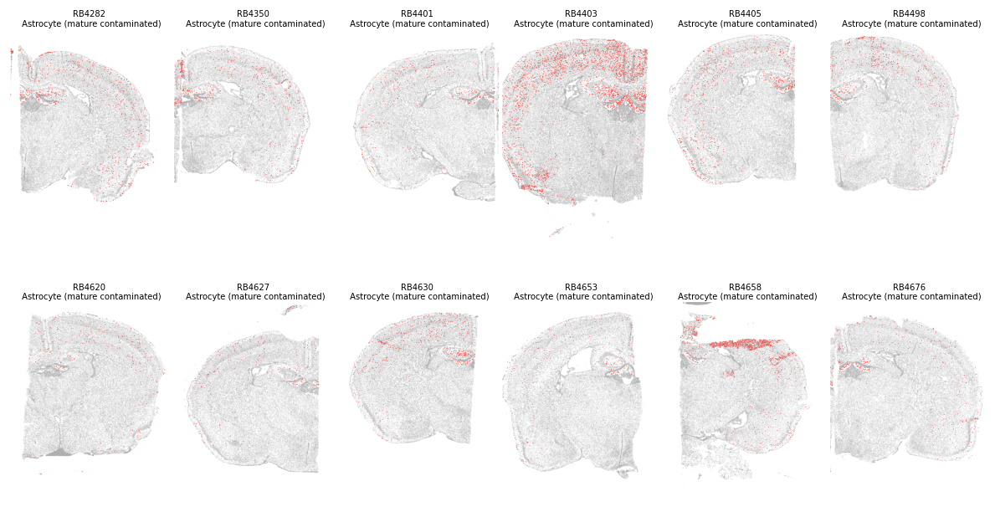

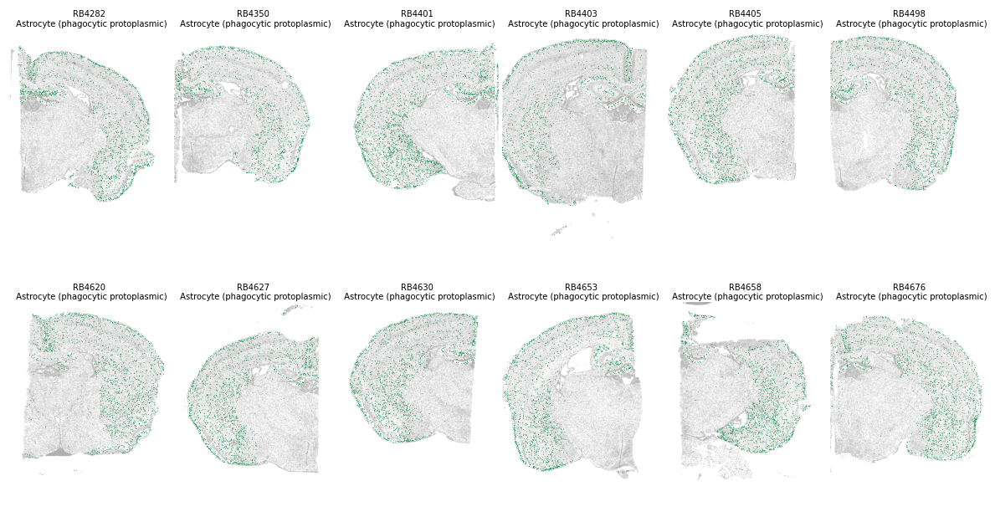

...

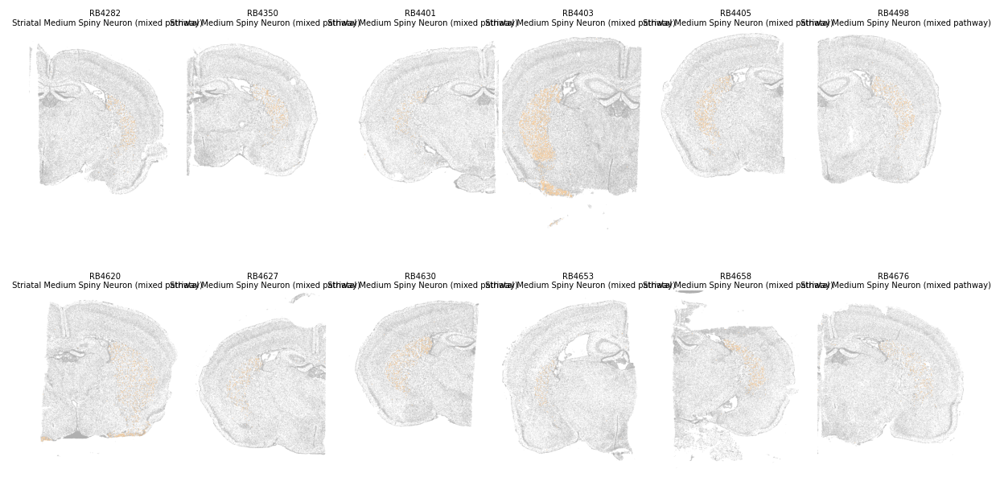

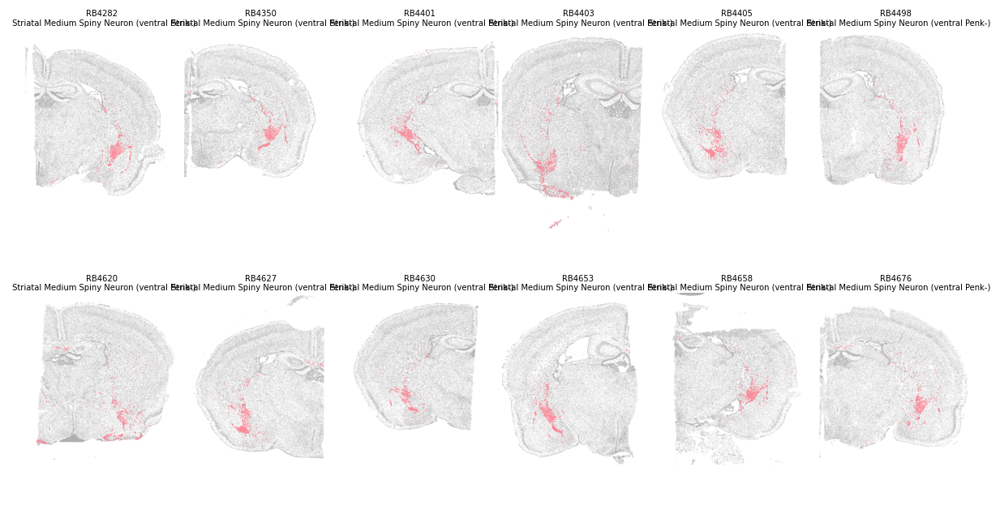

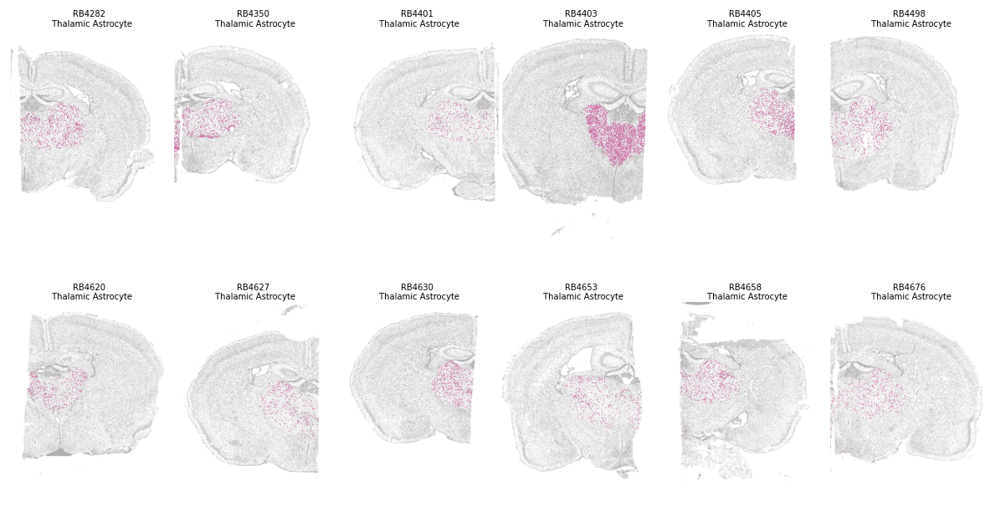

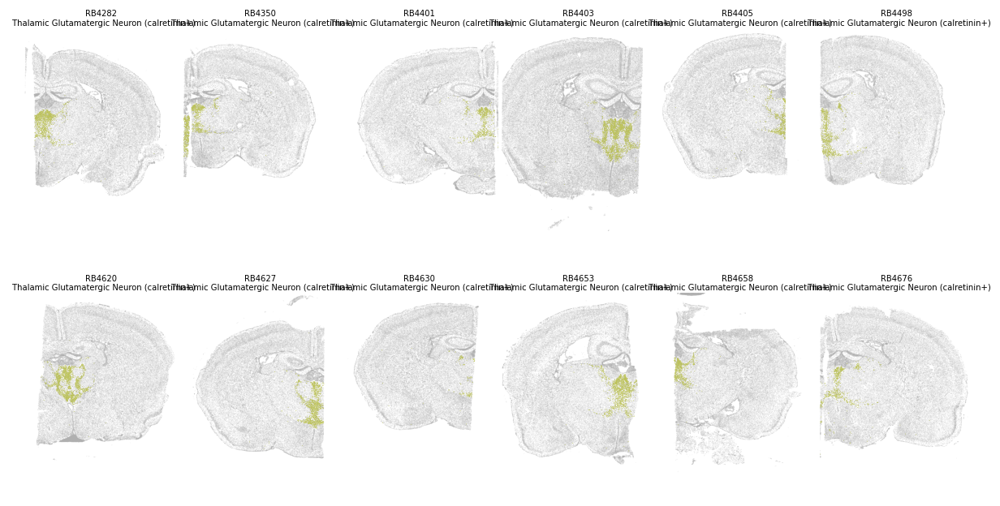

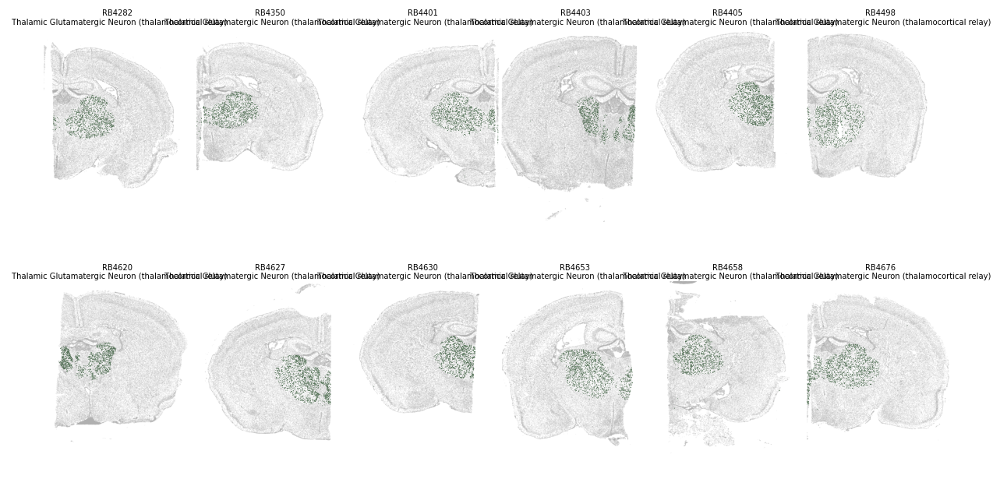

In [18]:
domain_key = "cytetype_annotation_leiden_3"

for cl in adata.obs[domain_key].astype("category").cat.categories:
    fig, _ = plot_spatial_highlight(
        adata,
        color=domain_key,
        highlight=cl,
        groupby="sample_id",
        spot_size=0.3,
        cols=6,
        height=7,
        flip_y=True,
        fix_limits=True
    )
    plt.show()
    # fig.savefig(os.path.join(outdir, f"{domain_key}_cluster_{cl}.png"), dpi=300, bbox_inches="tight")
    # plt.close(fig)

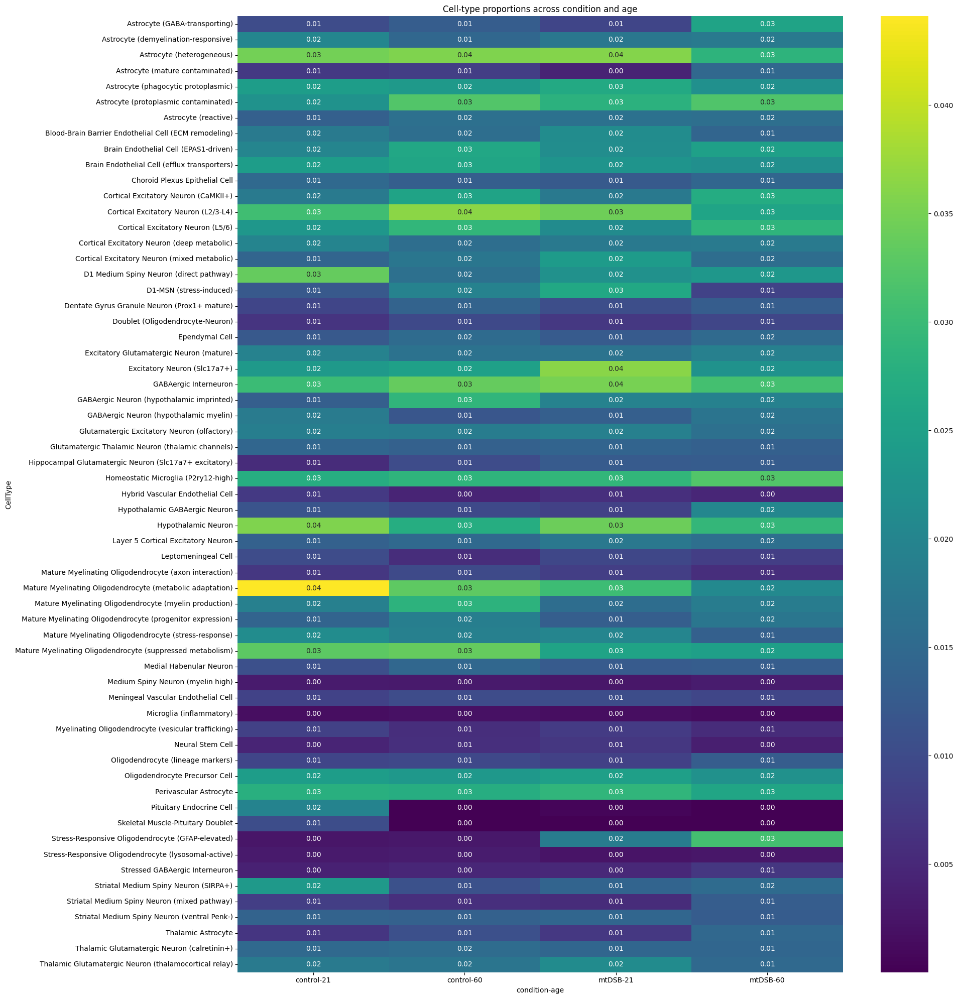

In [20]:
pivot = (
    counts.pivot_table(
        index="CellType", columns=["condition", "age"],
        values="Proportion", fill_value=0
    )
)

plt.figure(figsize=(20, 20))
sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f")
plt.title("Cell-type proportions across condition and age")
plt.tight_layout()
plt.show()

In [22]:
adata.write('/Users/christoffer/work/karolinska/development/oligo-mtDSB/data/mtDNA_DSB_5k_clustered_annotation_with_rbd_2_cytetype.h5ad')

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests


def cellstate_enrichment(
    adata,
    cell_pattern,
    annot_col="cytetype_annotation_leiden_2.5",
    groupby="course",
    alternative="greater",
    make_plot=True,
    title=None,
):
    """
    Test enrichment of a cell state (defined by string pattern in `annot_col`)
    across groups (e.g. disease course) using Fisher's exact test.
    """

    # --- handle categorical / any dtype safely: cast to string ---
    annot_series = adata.obs[annot_col].astype(str)
    is_state = annot_series.str.contains(cell_pattern, regex=False)

    # collect the actual cell types used in the test
    matched_cells = sorted(pd.unique(annot_series[is_state]))
    if matched_cells:
        if len(matched_cells) <= 4:
            cell_label = ", ".join(matched_cells)
        else:
            cell_label = ", ".join(matched_cells[:4]) + ", …"
    else:
        cell_label = f"(no '{cell_pattern}' match)"

    results = []
    for g in sorted(adata.obs[groupby].unique()):
        in_group = adata.obs[groupby] == g

        a = (is_state & in_group).sum()          # state in group
        b = (~is_state & in_group).sum()         # non-state in group
        c = (is_state & ~in_group).sum()         # state outside
        d = (~is_state & ~in_group).sum()        # non-state outside

        table = np.array([[a, b],
                          [c, d]], dtype=float)

        # Haldane–Anscombe correction for zeros
        if np.any(table == 0):
            table += 0.5

        oddsratio, pvalue = fisher_exact(table, alternative=alternative)
        results.append([g, int(a), int(b), int(c), int(d), oddsratio, pvalue])

    df_enrich = pd.DataFrame(
        results,
        columns=[groupby, "state_in_group", "non_state_in_group",
                 "state_outside", "non_state_outside",
                 "oddsratio", "pvalue"]
    )

    # --- FDR and log scales ---
    df_enrich["FDR"] = multipletests(df_enrich["pvalue"], method="fdr_bh")[1]
    df_enrich["log2OR"] = np.log2(df_enrich["oddsratio"].replace([np.inf, -np.inf], np.nan))
    df_enrich["neglog10_FDR"] = -np.log10(df_enrich["FDR"].replace(0, 1e-300))

    df_enrich = df_enrich.sort_values("log2OR", ascending=False)

    # --- Pretty plot ---
    if make_plot:
        plt.figure(figsize=(7, 5))
        cmap = sns.diverging_palette(220, 20, n=200, as_cmap=True)

        sns.barplot(
            data=df_enrich,
            y=groupby,
            x="log2OR",
            hue="log2OR",
            palette=cmap,
            dodge=False,
            edgecolor="black"
        )

        plt.axvline(0, linestyle="--", color="black", linewidth=1)

        if title is None:
            title = f"{cell_label} – enrichment by {groupby}"
        plt.title(title, fontsize=13, pad=12)
        plt.xlabel("log2(odds ratio)")
        plt.ylabel(groupby)

        plt.legend([], [], frameon=False)
        plt.tight_layout()
        plt.show()

    return df_enrich

In [27]:
adata.obs['condition-age'] = adata.obs['condition'].astype(str) + '-' + adata.obs['age'].astype(str)

Mature Myelinating Oligodendrocyte (progenitor expression)


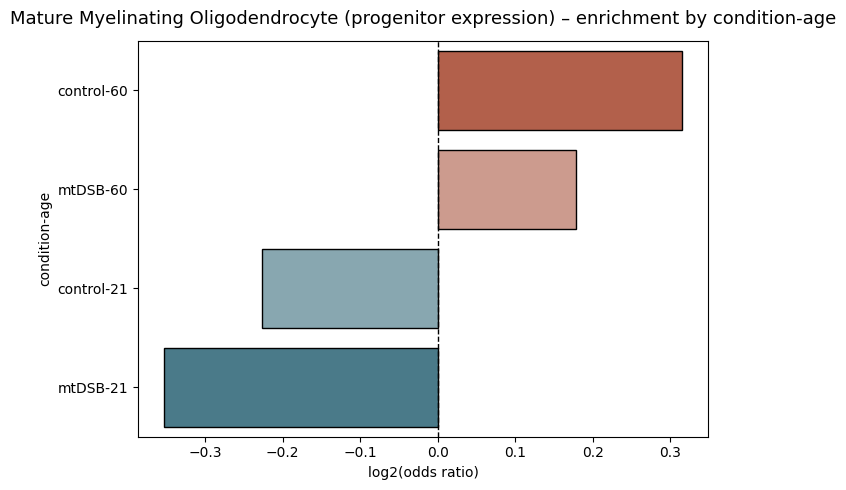

Layer 5 Cortical Excitatory Neuron


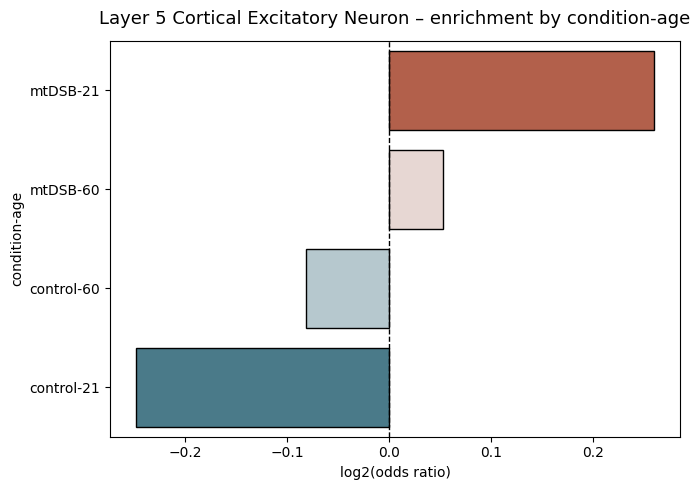

Cortical Excitatory Neuron (L5/6)


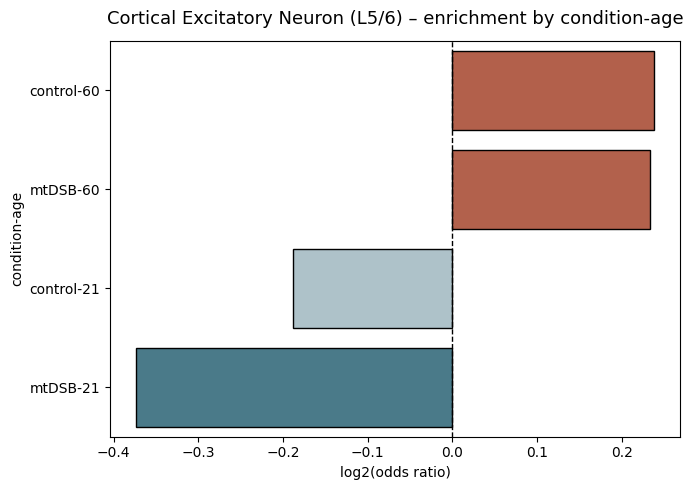

Mature Myelinating Oligodendrocyte (myelin production)


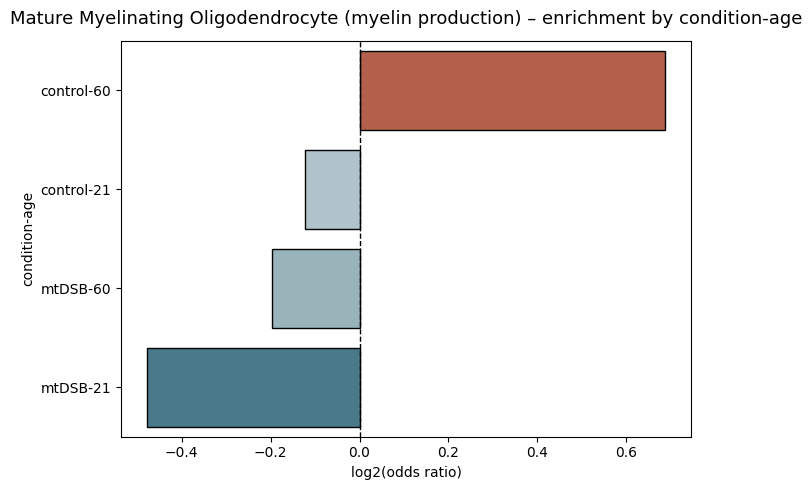

Astrocyte (demyelination-responsive)


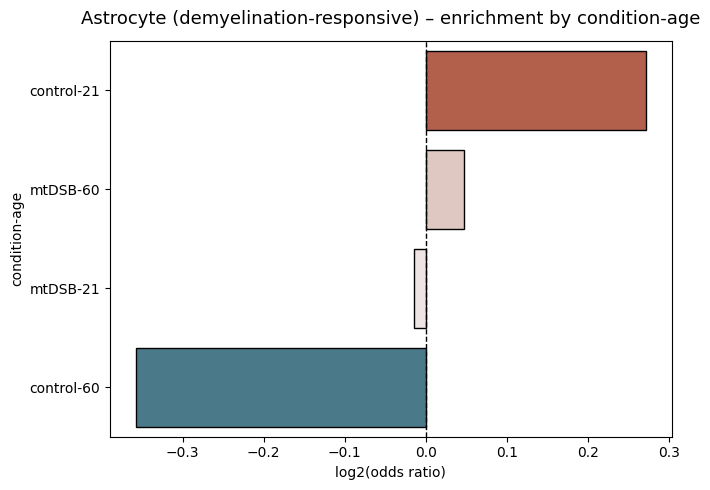

Mature Myelinating Oligodendrocyte (suppressed metabolism)


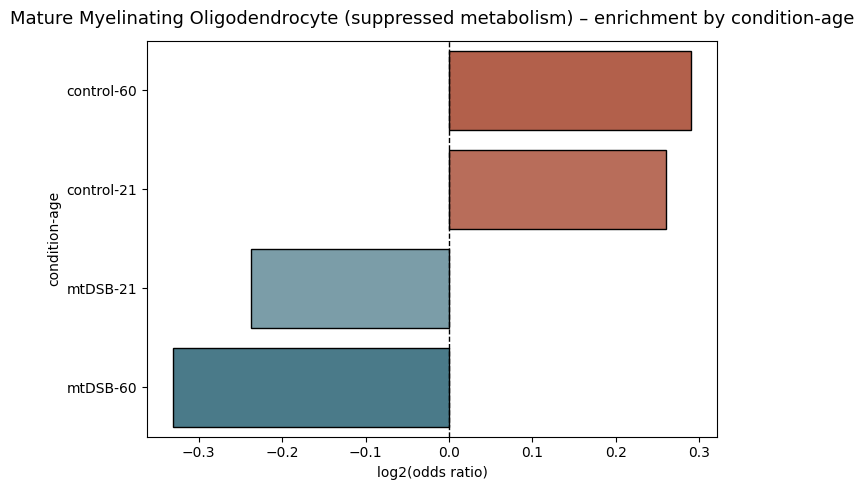

Homeostatic Microglia (P2ry12-high)


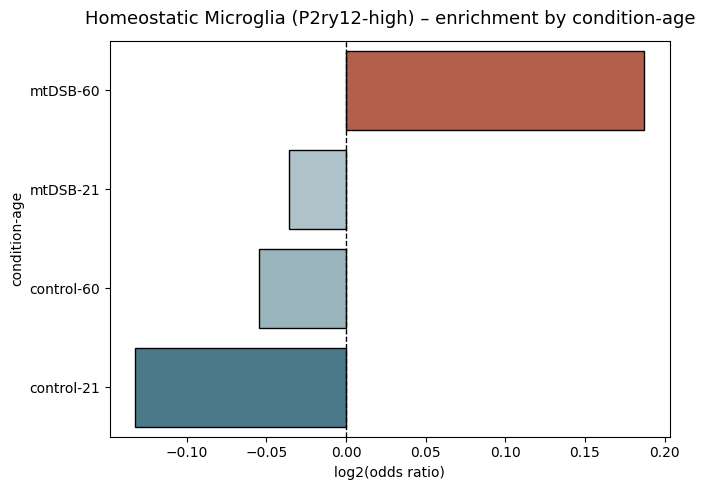

Cortical Excitatory Neuron (deep metabolic)


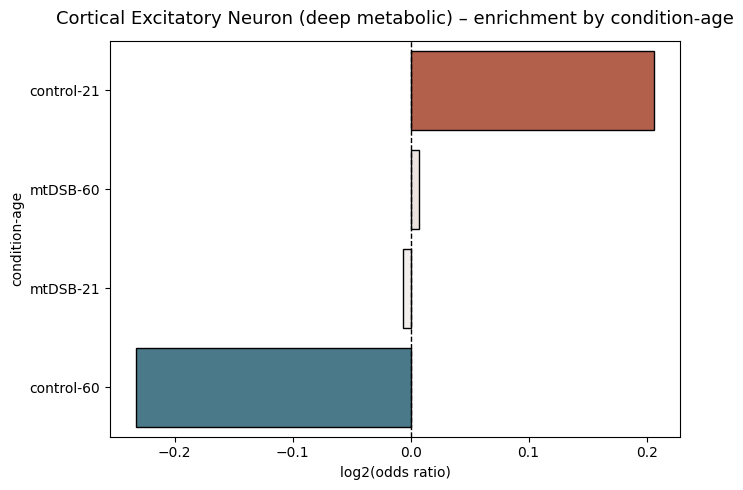

Cortical Excitatory Neuron (mixed metabolic)


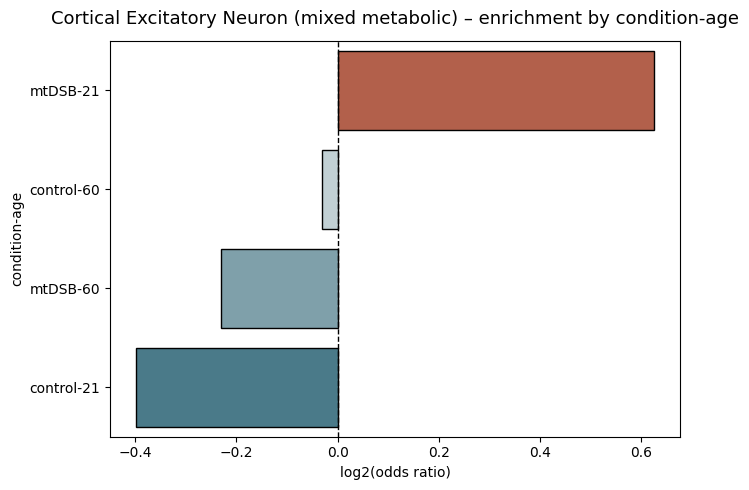

Cortical Excitatory Neuron (L2/3-L4)


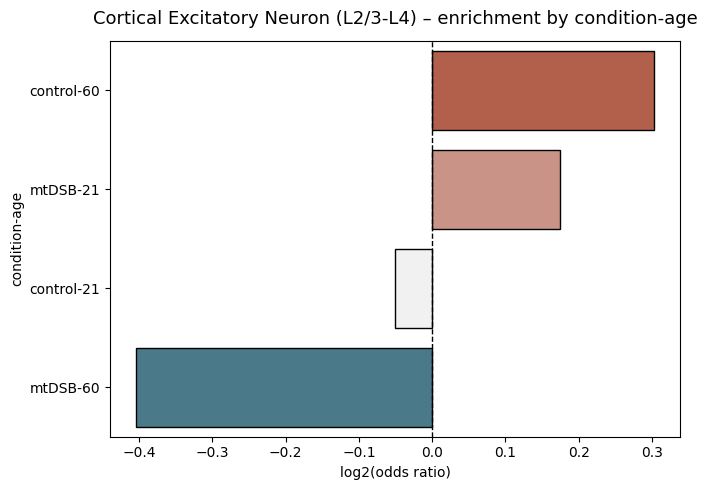

Astrocyte (mature contaminated)


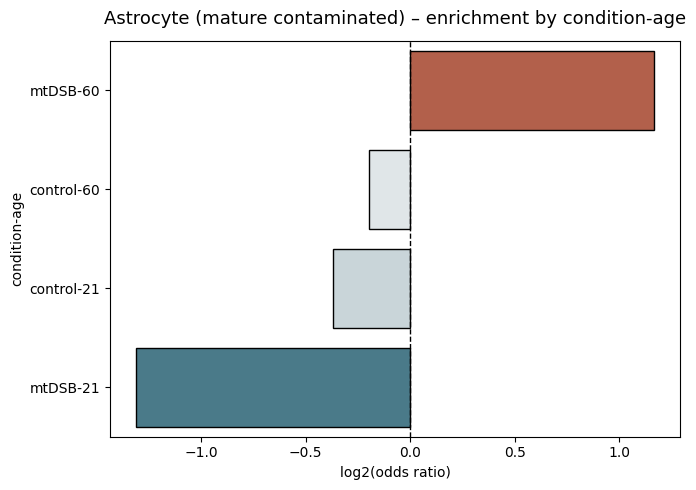

Leptomeningeal Cell


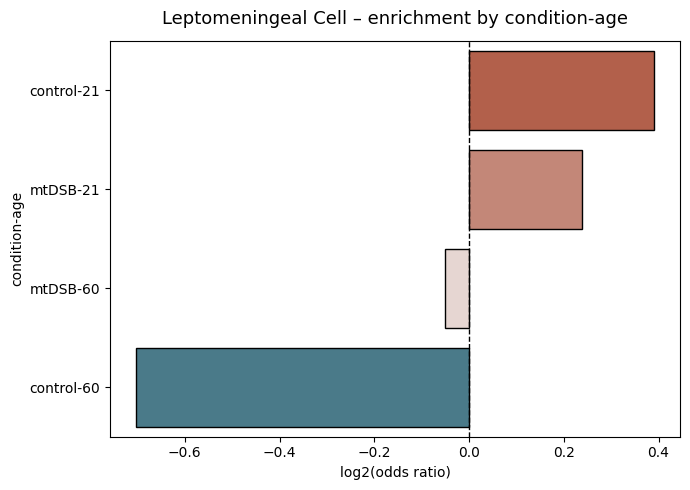

Doublet (Oligodendrocyte-Neuron)


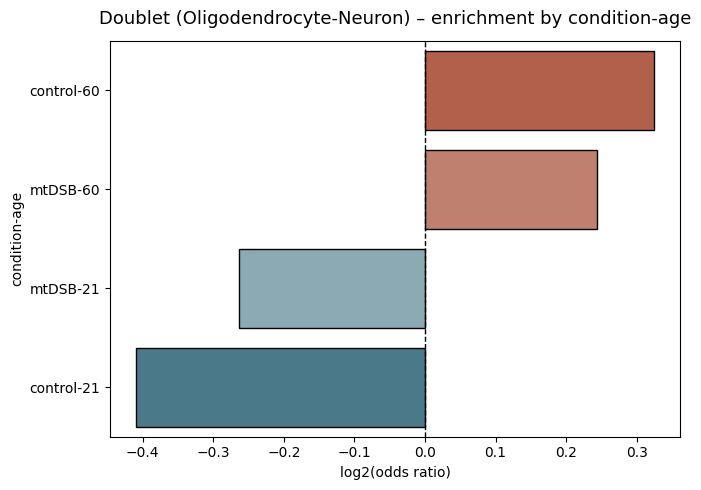

GABAergic Interneuron


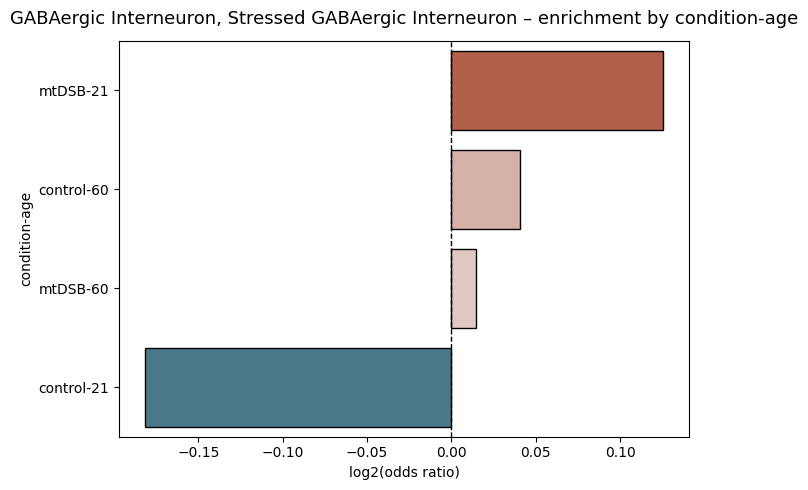

Astrocyte (phagocytic protoplasmic)


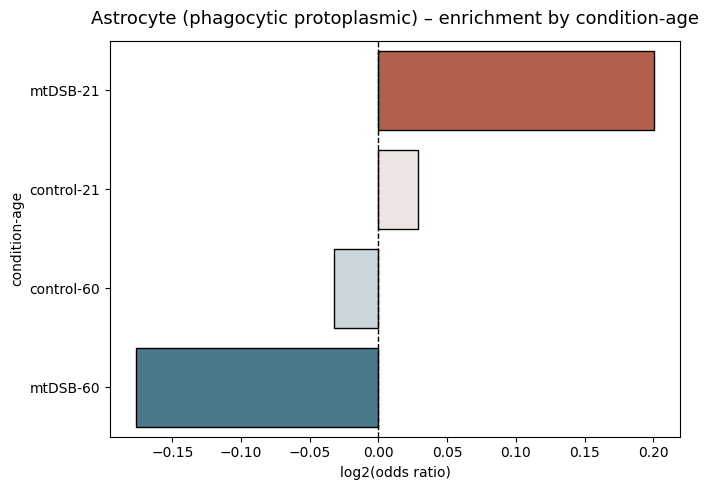

Mature Myelinating Oligodendrocyte (stress-response)


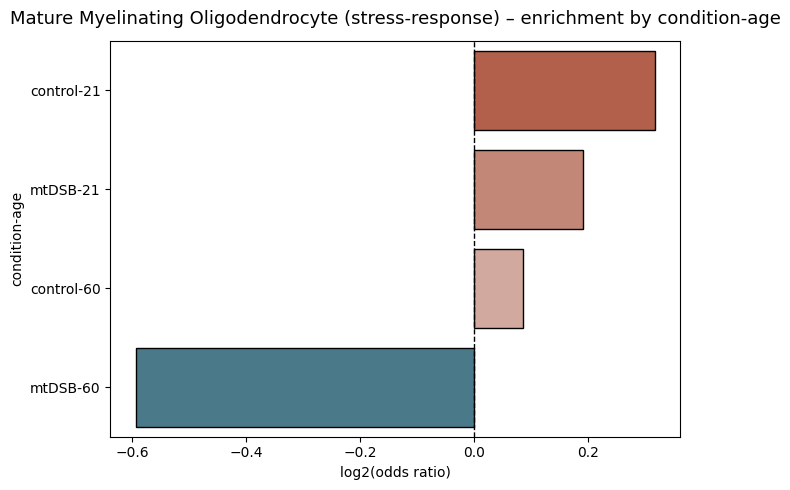

Stress-Responsive Oligodendrocyte (lysosomal-active)


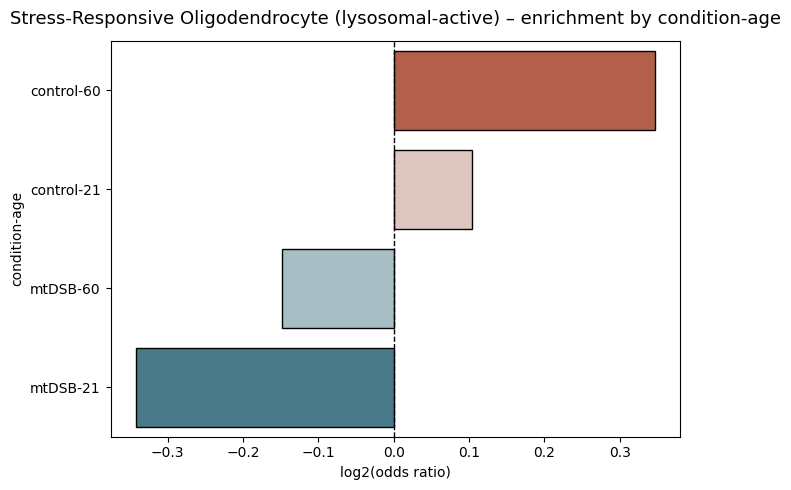

Mature Myelinating Oligodendrocyte (metabolic adaptation)


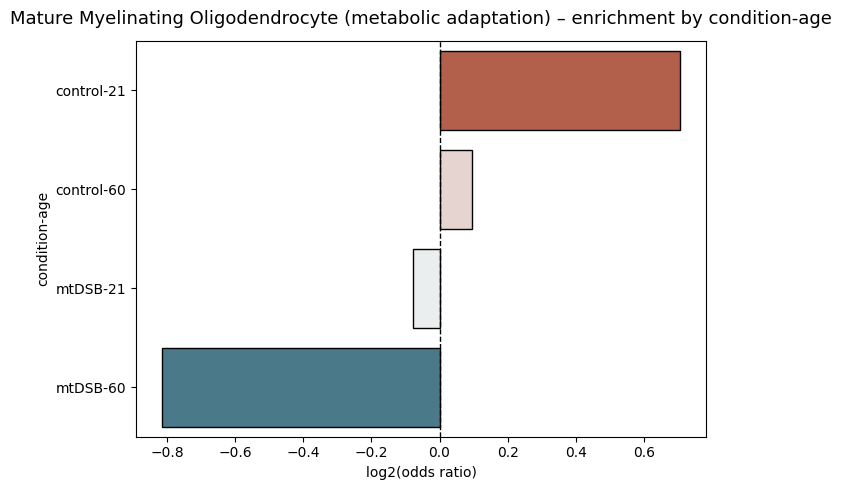

Excitatory Neuron (Slc17a7+)


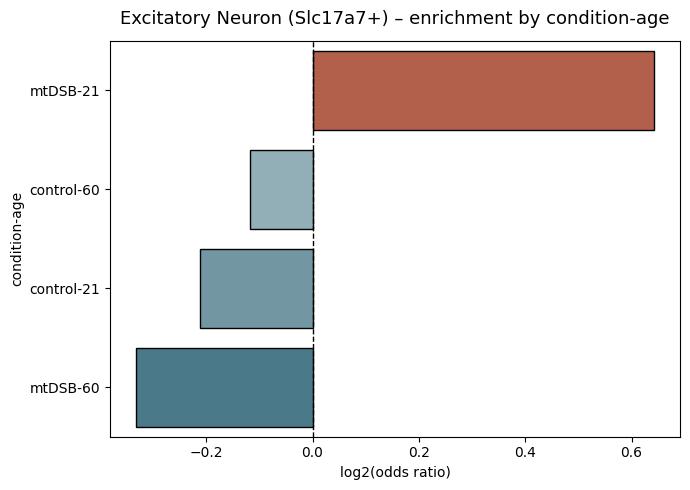

Oligodendrocyte Precursor Cell


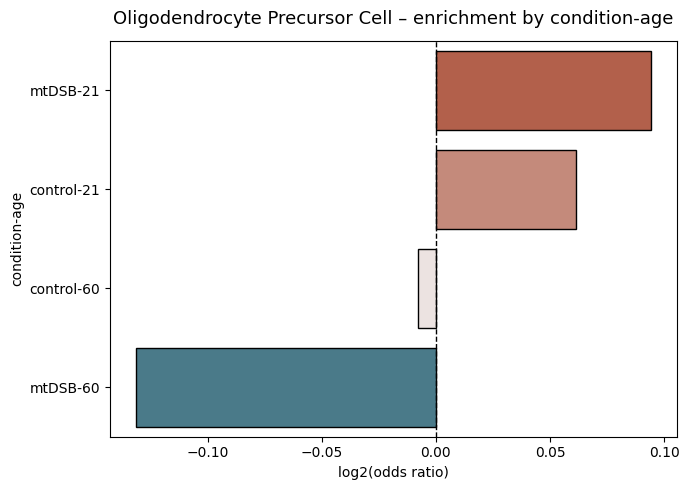

Brain Endothelial Cell (EPAS1-driven)


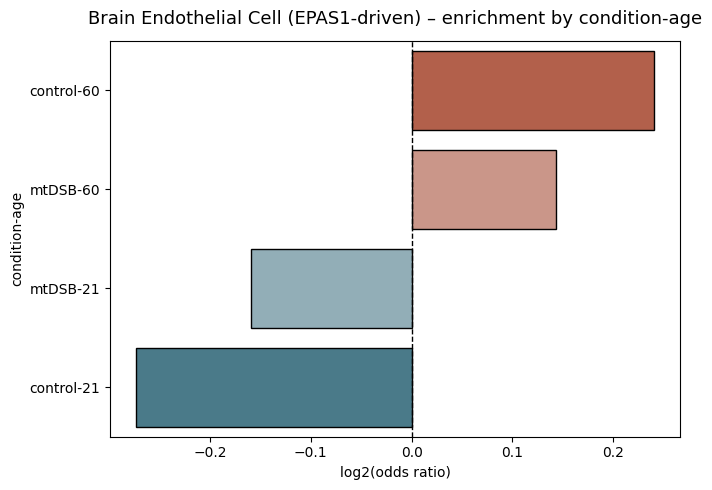

Blood-Brain Barrier Endothelial Cell (ECM remodeling)


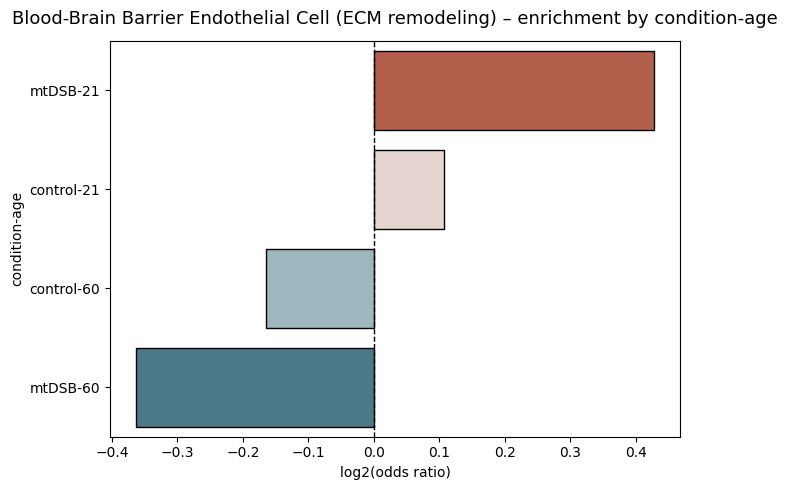

Astrocyte (reactive)


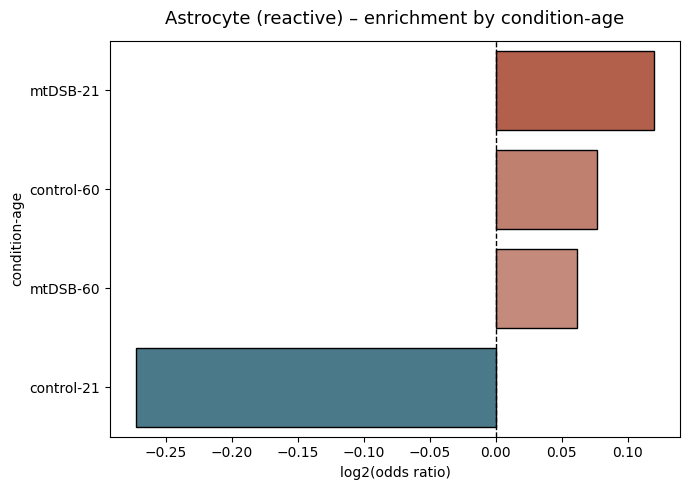

Perivascular Astrocyte


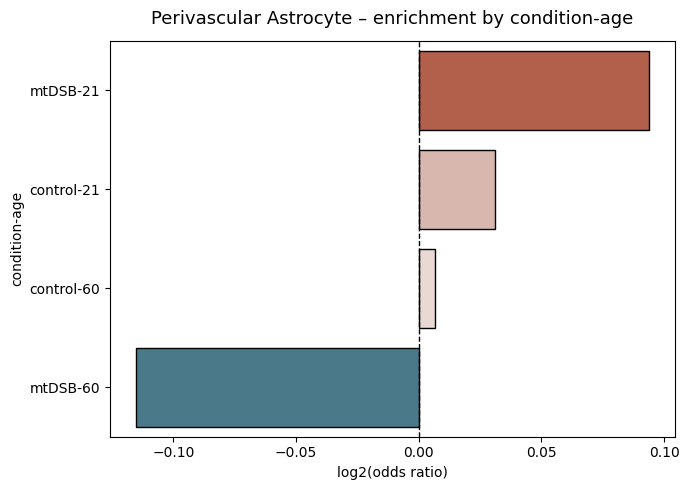

Hybrid Vascular Endothelial Cell


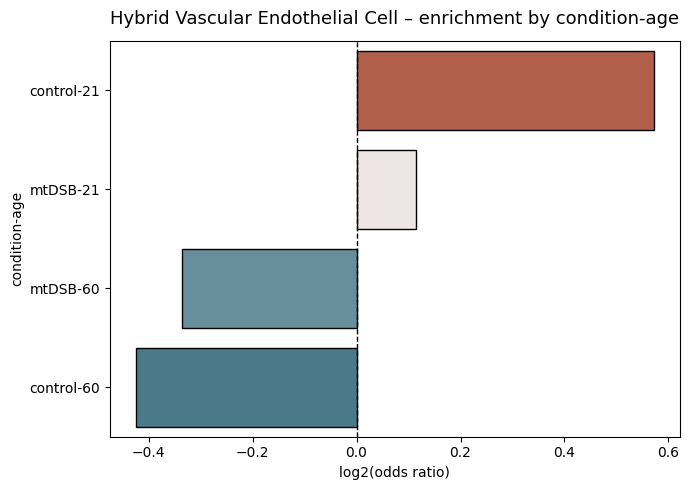

Cortical Excitatory Neuron (CaMKII+)


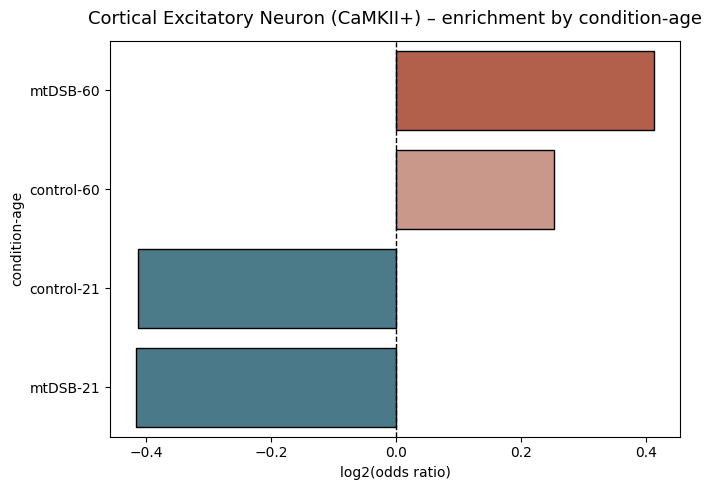

Neural Stem Cell


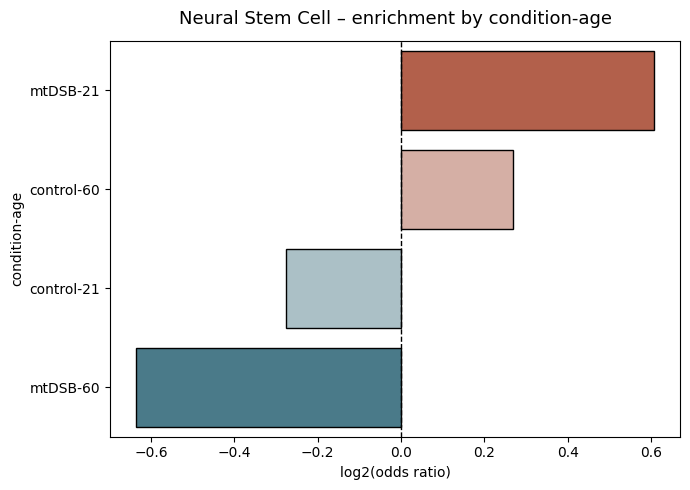

Ependymal Cell


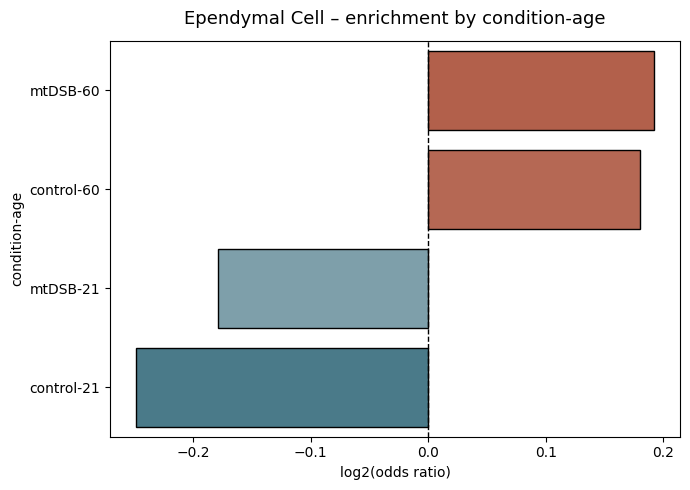

Microglia (inflammatory)


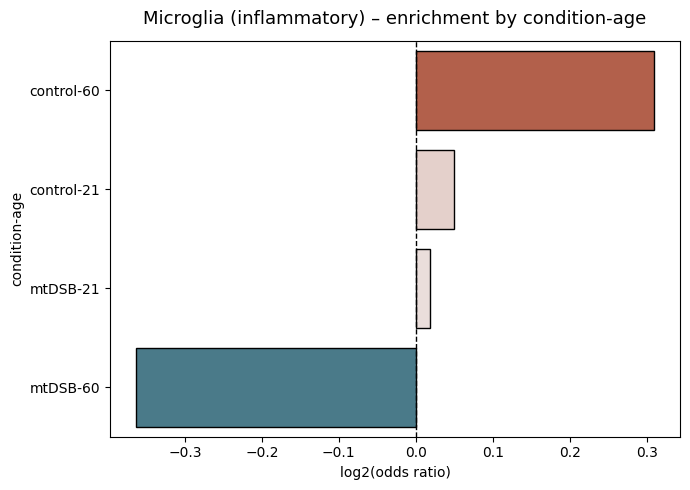

Striatal Medium Spiny Neuron (ventral Penk-)


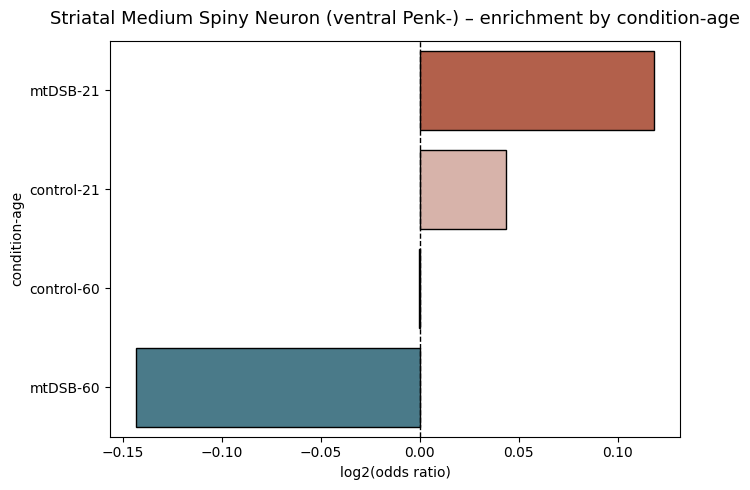

Medial Habenular Neuron


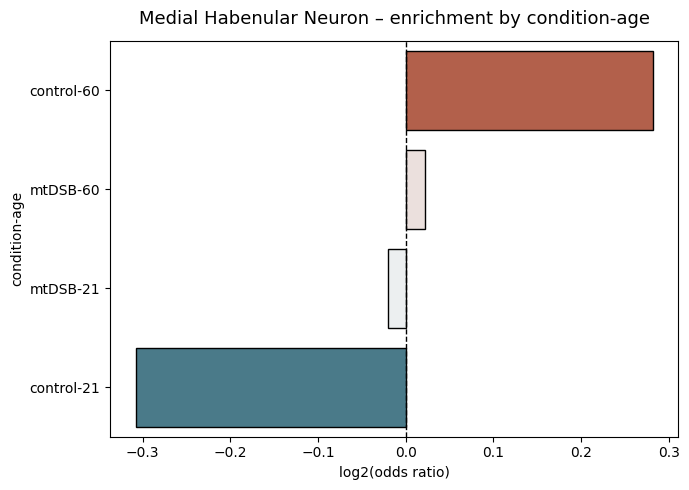

Dentate Gyrus Granule Neuron (Prox1+ mature)


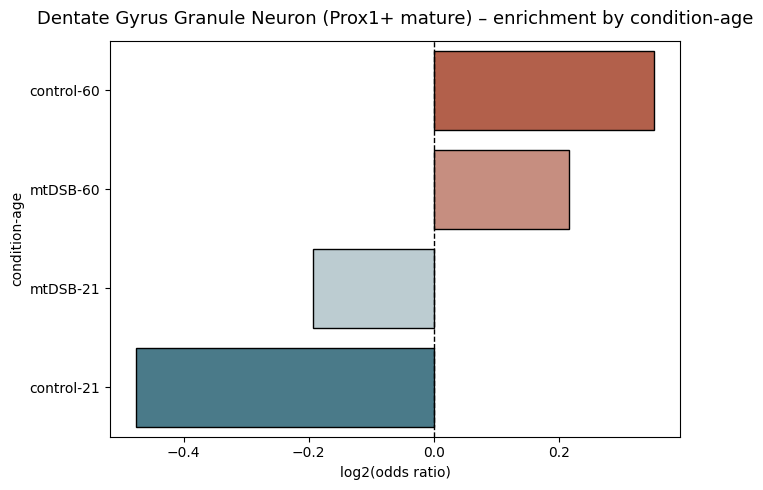

Choroid Plexus Epithelial Cell


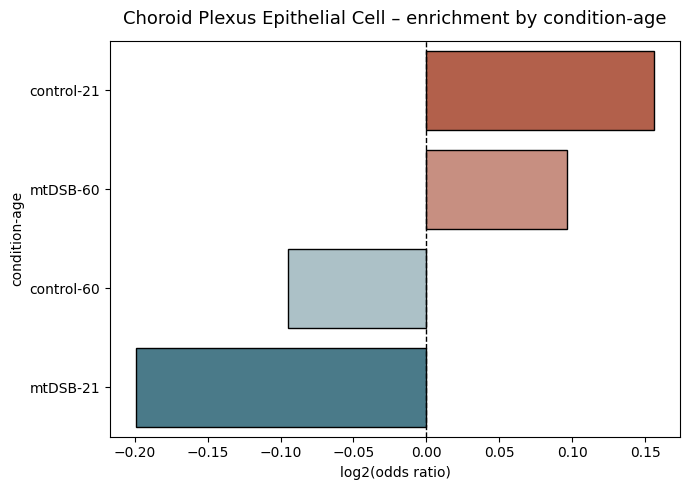

Meningeal Vascular Endothelial Cell


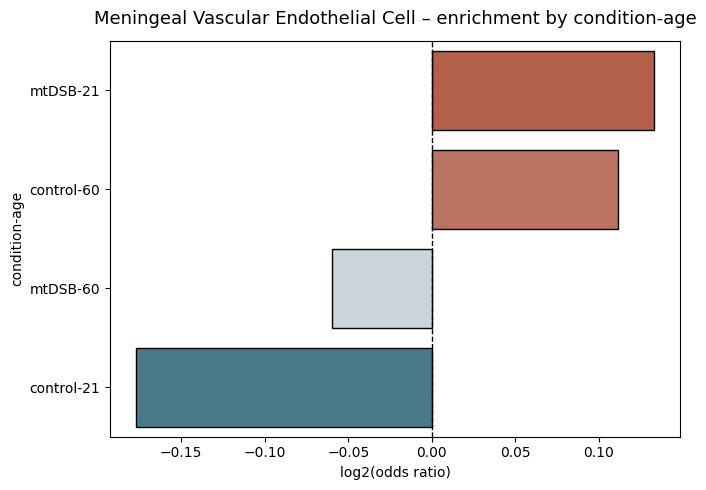

Myelinating Oligodendrocyte (vesicular trafficking)


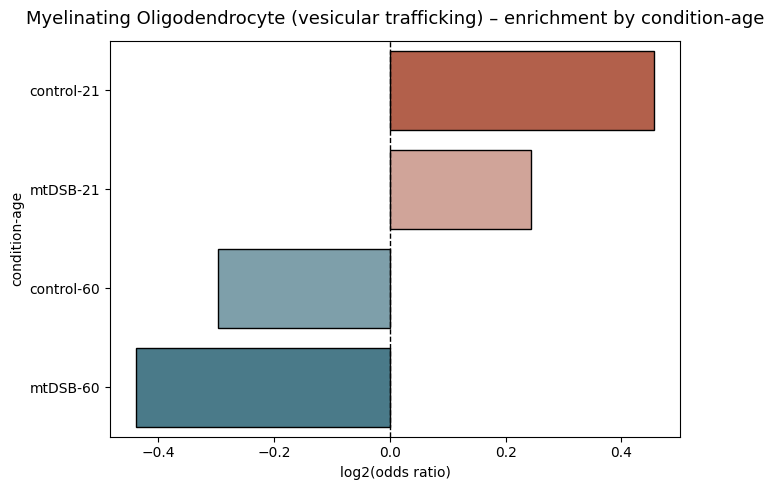

Brain Endothelial Cell (efflux transporters)


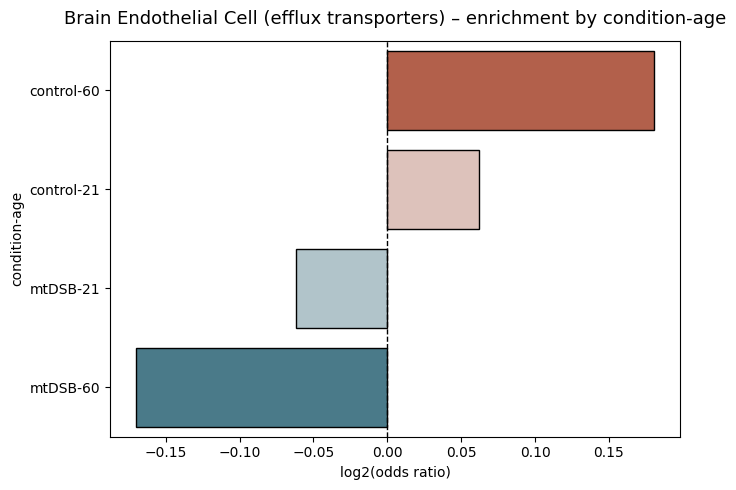

Oligodendrocyte (lineage markers)


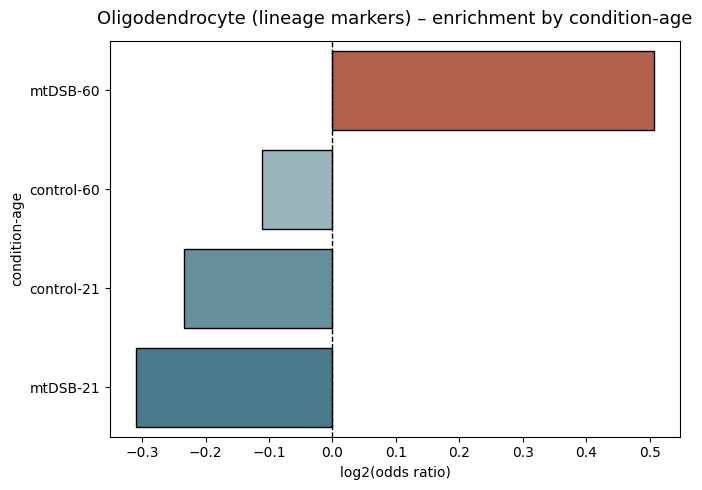

Hippocampal Glutamatergic Neuron (Slc17a7+ excitatory)


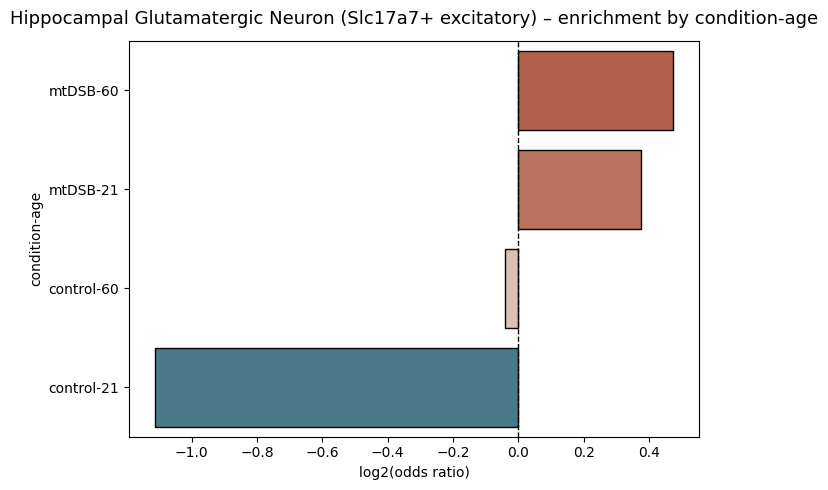

D1-MSN (stress-induced)


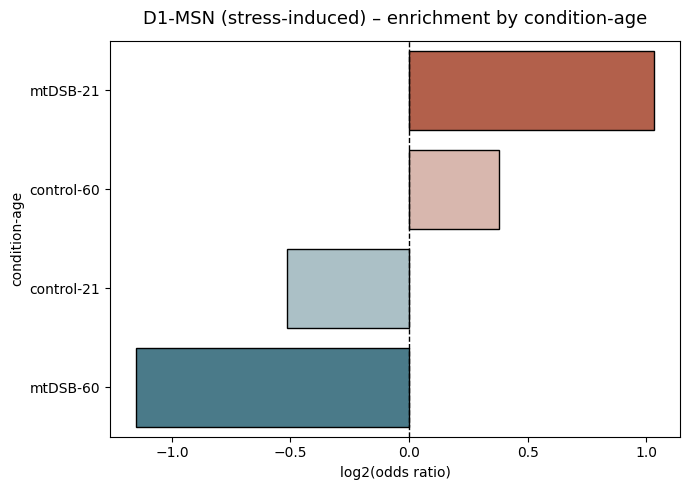

Astrocyte (GABA-transporting)


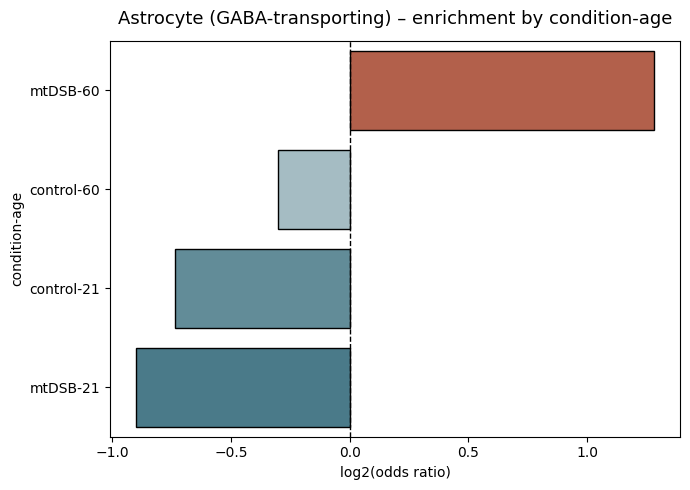

Astrocyte (heterogeneous)


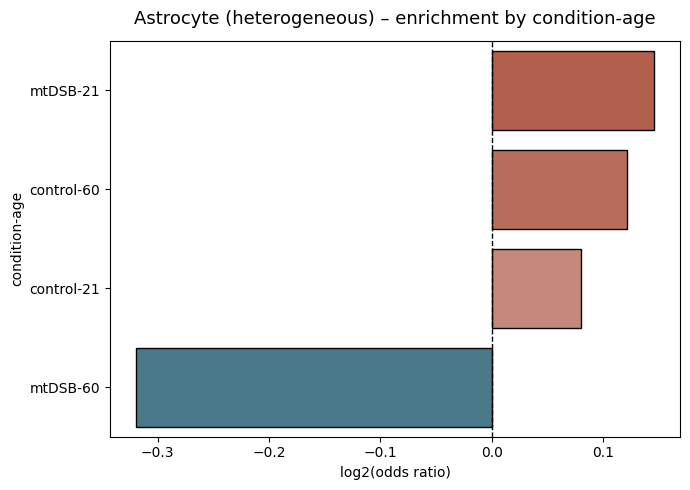

Glutamatergic Excitatory Neuron (olfactory)


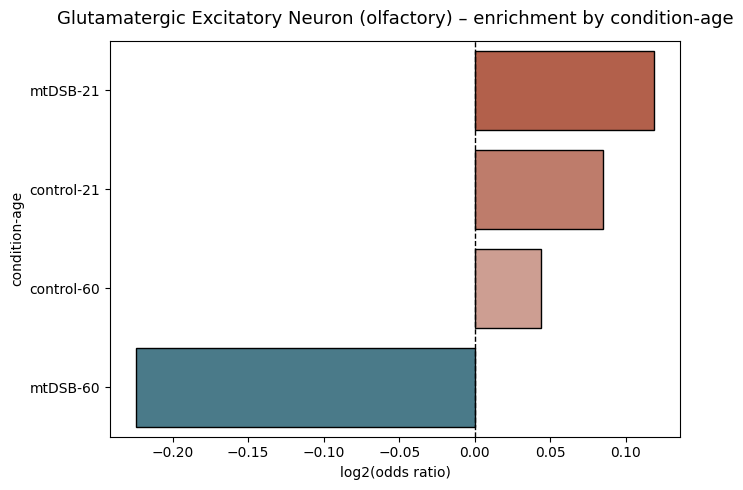

GABAergic Neuron (hypothalamic imprinted)


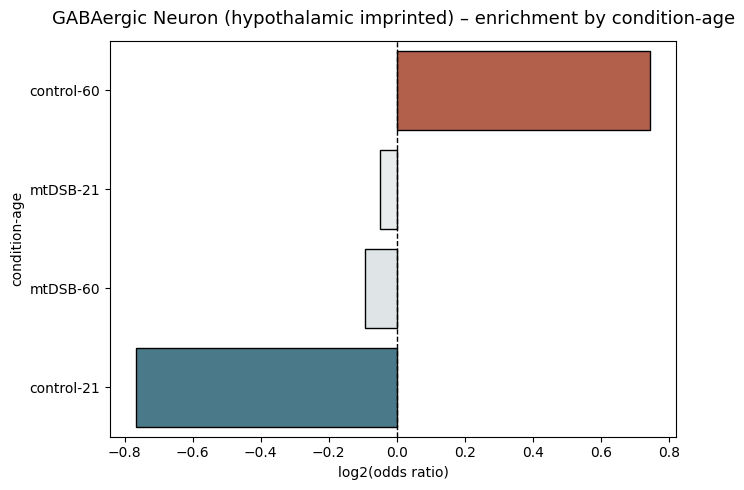

Excitatory Glutamatergic Neuron (mature)


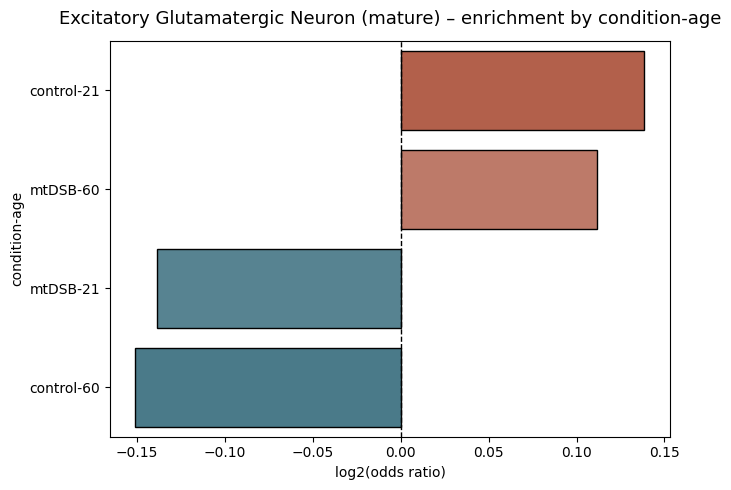

Hypothalamic GABAergic Neuron


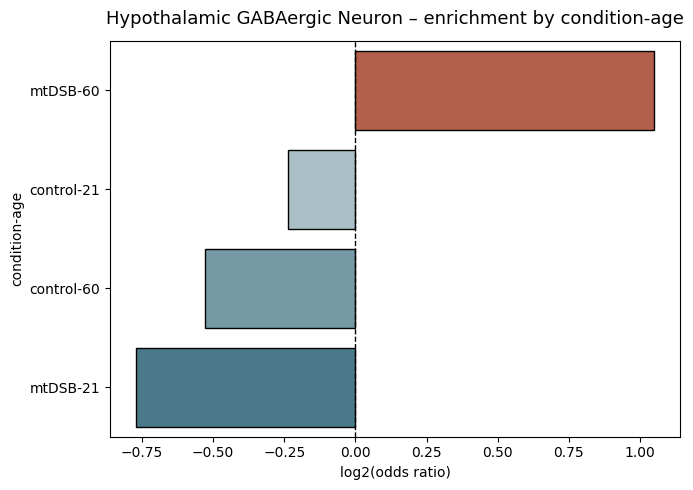

Hypothalamic Neuron


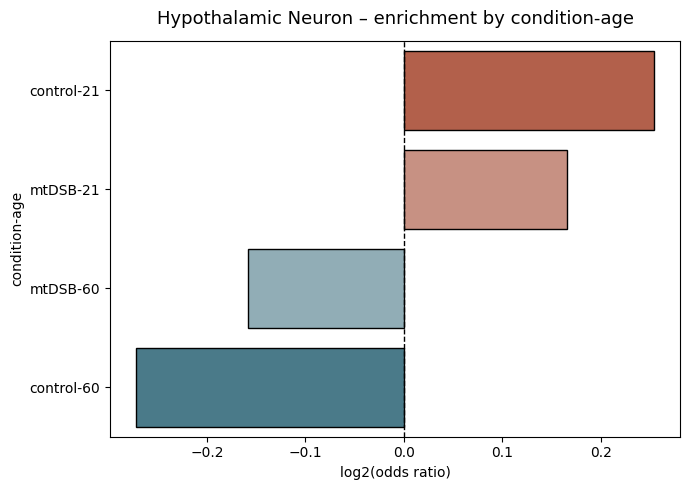

GABAergic Neuron (hypothalamic myelin)


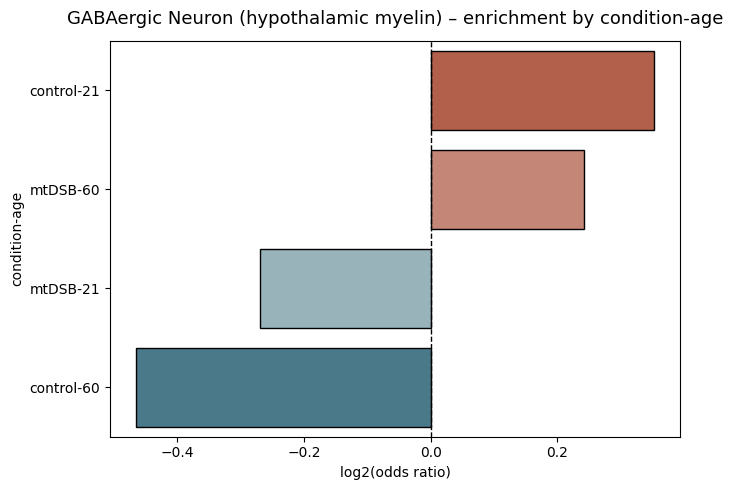

Astrocyte (protoplasmic contaminated)


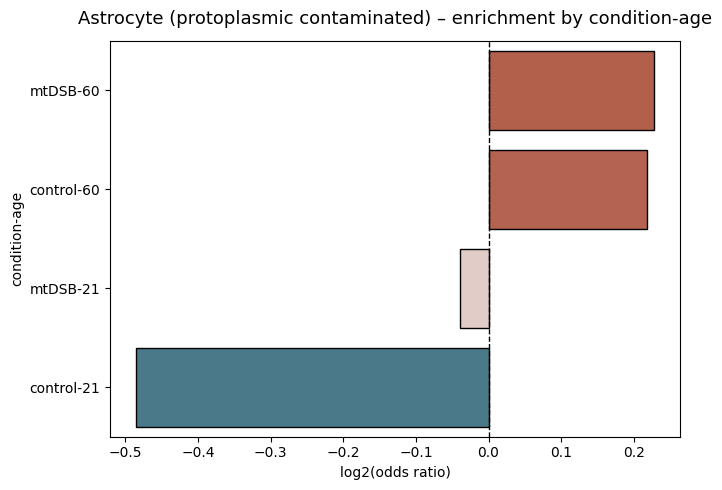

Thalamic Glutamatergic Neuron (calretinin+)


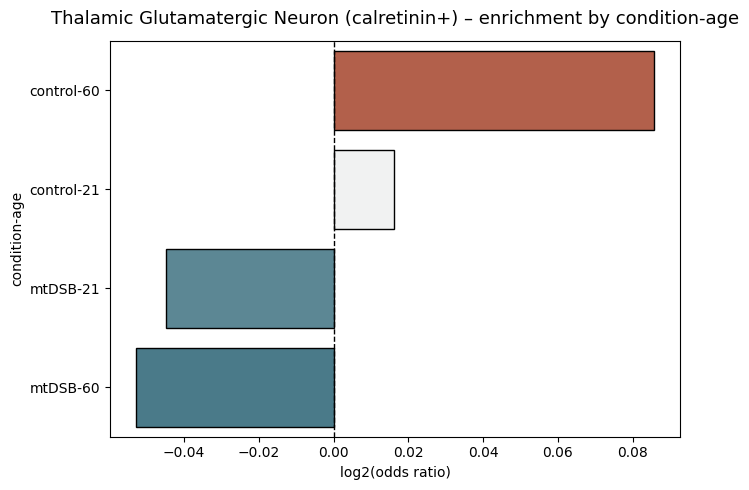

Medium Spiny Neuron (myelin high)


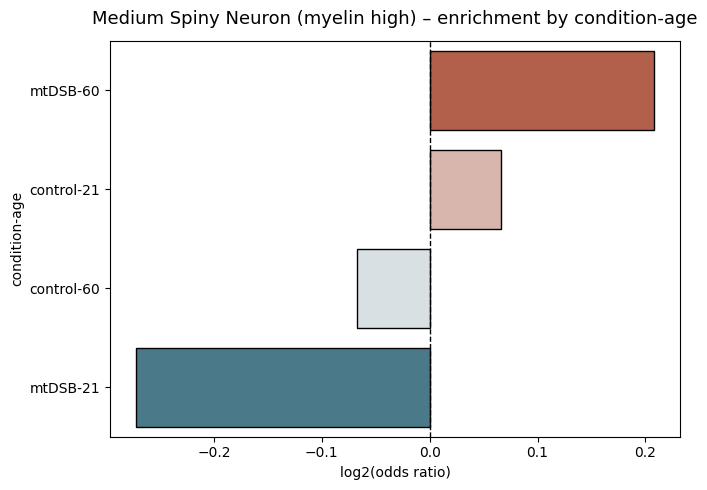

D1 Medium Spiny Neuron (direct pathway)


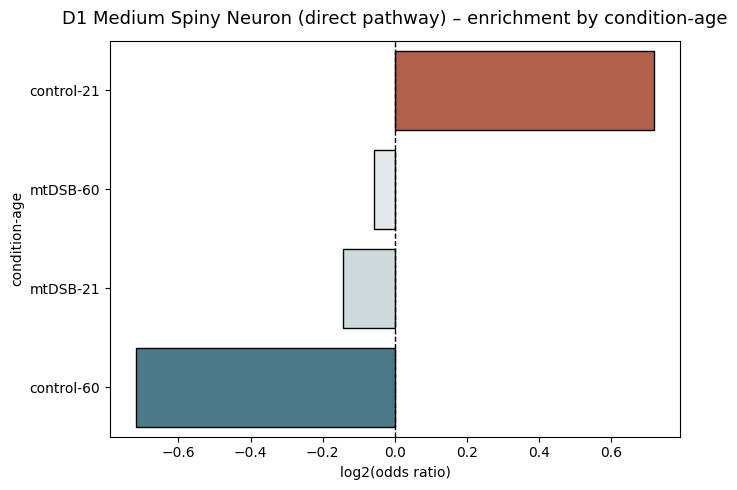

Mature Myelinating Oligodendrocyte (axon interaction)


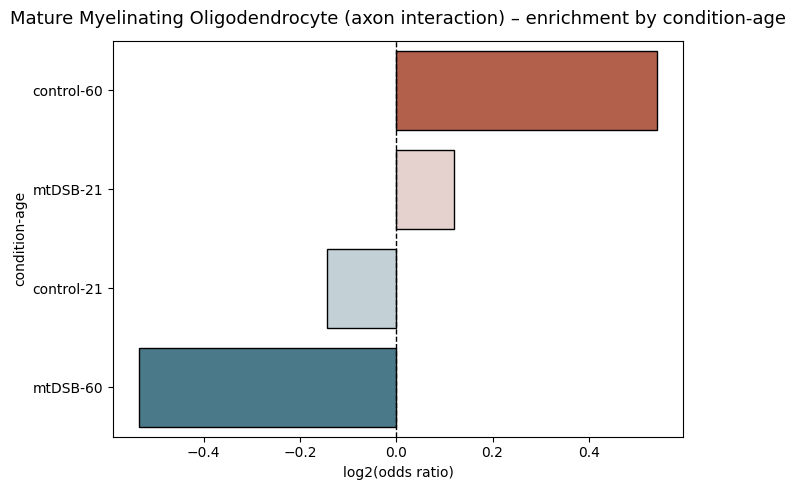

Thalamic Glutamatergic Neuron (thalamocortical relay)


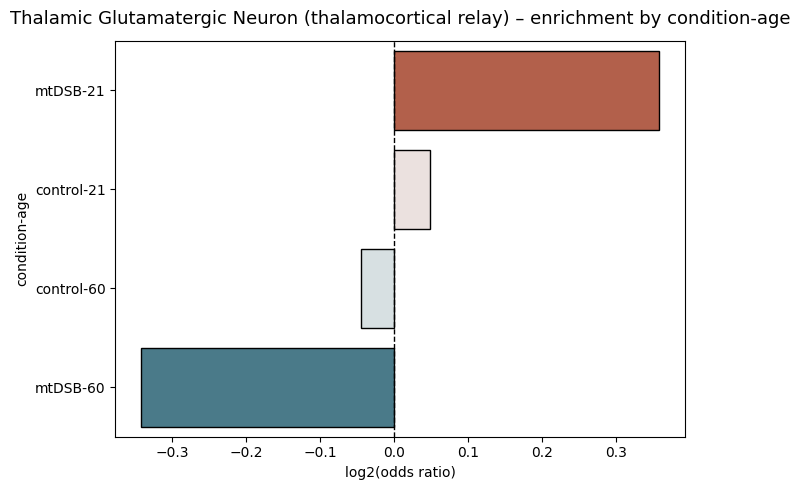

Glutamatergic Thalamic Neuron (thalamic channels)


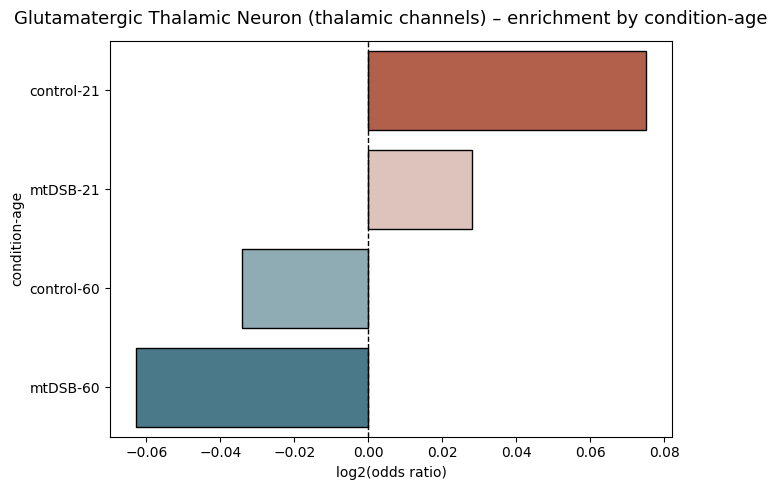

Stressed GABAergic Interneuron


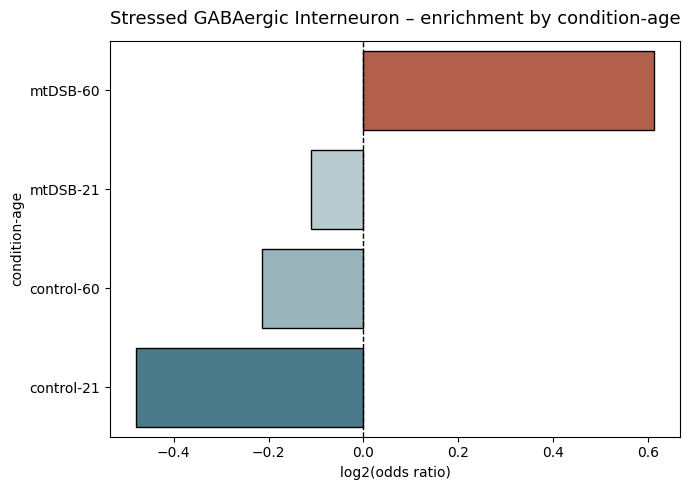

Pituitary Endocrine Cell


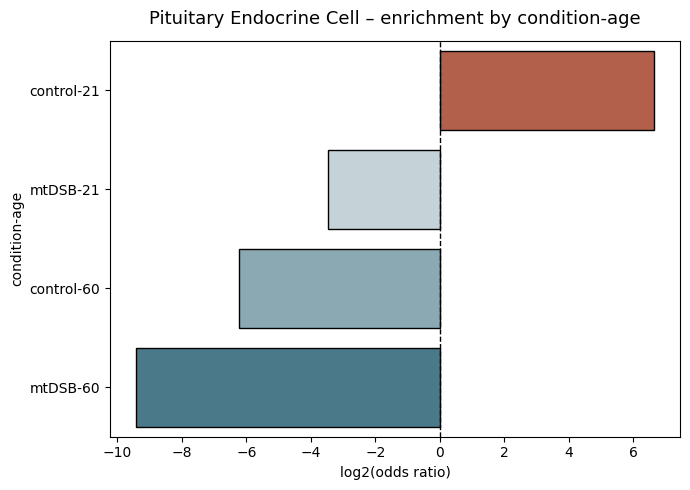

Skeletal Muscle-Pituitary Doublet


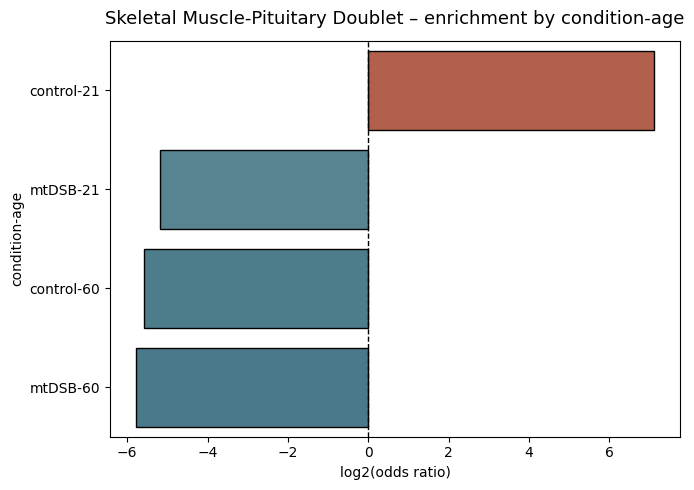

Stress-Responsive Oligodendrocyte (GFAP-elevated)


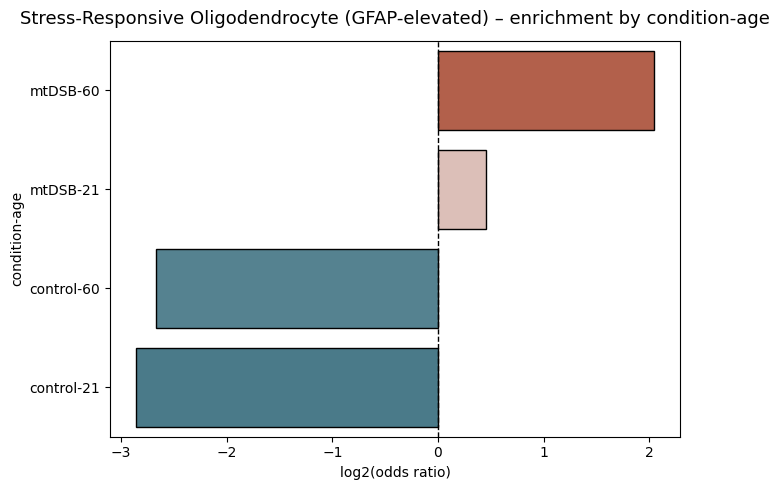

Thalamic Astrocyte


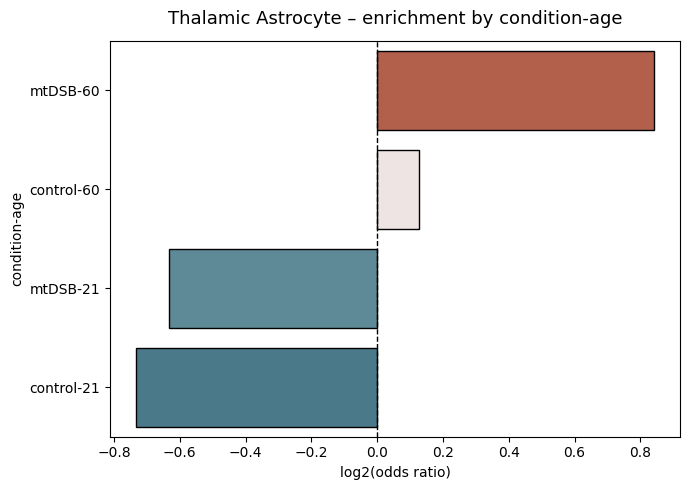

Striatal Medium Spiny Neuron (mixed pathway)


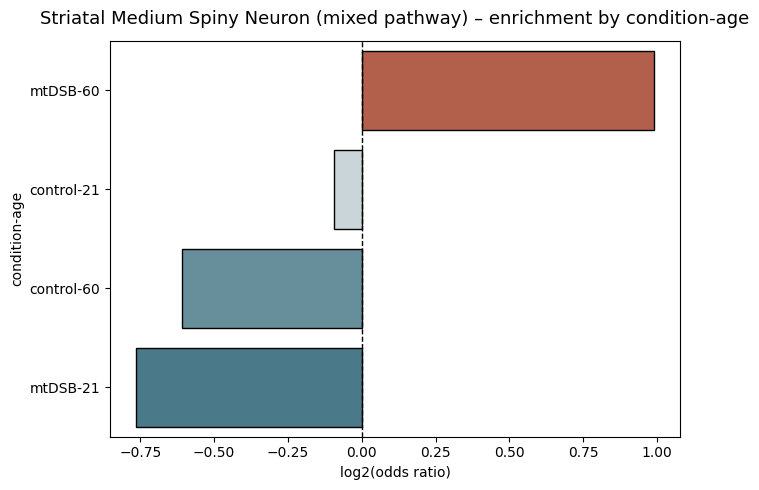

Striatal Medium Spiny Neuron (SIRPA+)


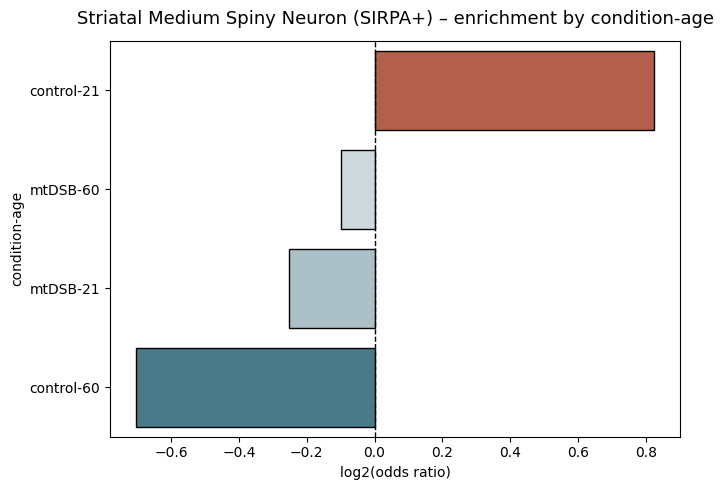

In [34]:
for cell in adata.obs.cytetype_annotation_leiden_3.unique():
    print(cell)
    cellstate_enrichment(
        adata,
        cell_pattern=cell,
        annot_col="cytetype_annotation_leiden_3",
        groupby="condition-age"
    )


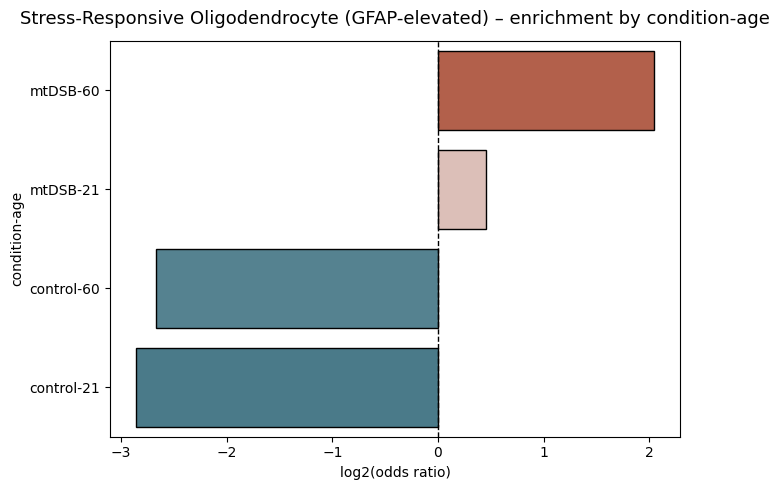

,condition-age,state_in_group,non_state_in_group,state_outside,non_state_outside,oddsratio,pvalue,FDR,log2OR,neglog10_FDR
3,mtDSB-60,8937,279585,5320,686632,4.125630,0.000000e+00,0.000000e+00,2.044615,300.00000
2,mtDSB-21,4029,215977,10228,750240,1.368356,3.257991e-60,6.515982e-60,0.452444,59.18602
1,control-60,666,229620,13591,736597,0.157197,1.000000e+00,1.000000e+00,-2.669358,-0.00000
0,control-21,625,241035,13632,725182,0.137939,1.000000e+00,1.000000e+00,-2.857897,-0.00000


In [32]:
cellstate_enrichment(
    adata,
    cell_pattern="GFAP",
    annot_col="cytetype_annotation_leiden_3",
    groupby="condition-age"
)


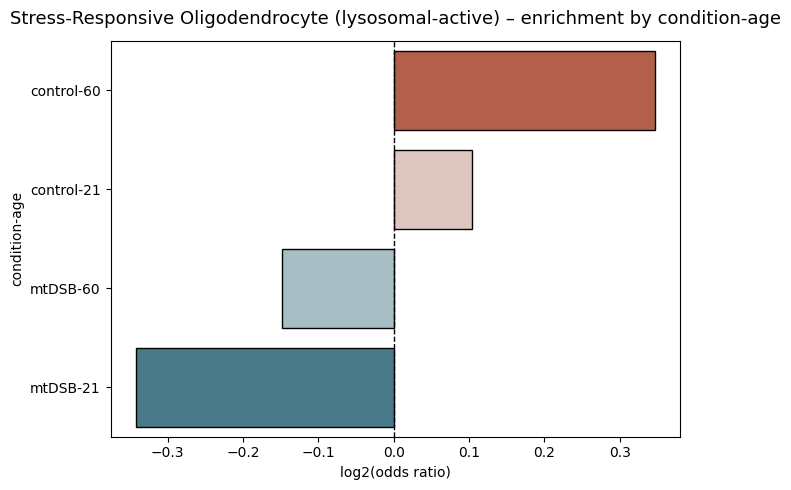

,condition-age,state_in_group,non_state_in_group,state_outside,non_state_outside,oddsratio,pvalue,FDR,log2OR,neglog10_FDR
1,control-60,792,229494,2031,748157,1.271267,1.077442e-08,4.309769e-08,0.346267,7.365546e+00
0,control-21,734,240926,2089,736725,1.074433,5.018463e-02,1.003693e-01,0.103576,9.983993e-01
3,mtDSB-60,772,287750,2051,689901,0.902450,9.931304e-01,9.999998e-01,-0.148081,1.080230e-07
2,mtDSB-21,525,219481,2298,758170,0.789185,9.999998e-01,9.999998e-01,-0.341564,1.080230e-07


In [30]:
cellstate_enrichment(
    adata,
    cell_pattern="lyso",
    annot_col="cytetype_annotation_leiden_3",
    groupby="condition-age"
)
